# Experimentos OLS · Propiedades nuevas

**Protocolo común.** Objetivo `log_price_rub`; precios en RUB mediante `exp(pred_log) × smearing` de Duan, estimado solo con los residuos del ajuste.
Train/Test cronológico: 6.400/1.600 anuncios, con desempate por ID el 05/04/2025. Holdout interno: 5.120/1.280, desde el 28/05/2024.
La preparación aprende parámetros solo en el ámbito de ajuste. Los siete diseños y los resultados históricos se conservan; el código auxiliar queda plegado.


In [ ]:
# Bloque original 1
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.linalg import qr
from IPython.display import display
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 180)
bases = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
rutas_candidatas = [p / 'data' / 'newbuilds_ols.csv' for p in bases]
rutas_candidatas += [p / 'Propiedades_Nuevas' / 'data' / 'newbuilds_ols.csv' for p in bases]
rutas_candidatas += [p / 'Ventas' / 'Propiedades_Nuevas' / 'data' / 'newbuilds_ols.csv' for p in bases]
ruta_datos = next((p for p in rutas_candidatas if p.is_file()), None)
if ruta_datos is None:
    raise FileNotFoundError('No se encontró Propiedades_Nuevas/data/newbuilds_ols.csv.')
df_original = pd.read_csv(ruta_datos, parse_dates=['date_posted_dt'], float_precision='round_trip')
df_modelado = df_original.copy(deep=True)
objetivo = 'log_price_rub'
metadatos_columnas = ['id', 'complex_id', 'date_posted_dt']
columnas_reservadas = metadatos_columnas + ['price_rub', objetivo]
assert set(columnas_reservadas).issubset(df_modelado.columns)
assert df_modelado.shape == (8000, 160)
assert df_modelado.columns.is_unique and df_modelado.id.notna().all() and df_modelado.id.is_unique
assert df_modelado.complex_id.notna().all() and df_modelado.date_posted_dt.notna().all()
assert pd.api.types.is_datetime64_any_dtype(df_modelado.date_posted_dt)
assert not df_modelado.duplicated().any()
columnas_candidatas = [c for c in df_modelado if c not in columnas_reservadas]
assert all((pd.api.types.is_numeric_dtype(df_modelado[c]) and (not pd.api.types.is_bool_dtype(df_modelado[c])) for c in columnas_candidatas + [objetivo, 'price_rub']))
assert np.isfinite(df_modelado[[objetivo, 'price_rub']].to_numpy()).all()
assert df_modelado.price_rub.gt(0).all()
assert np.allclose(np.exp(df_modelado[objetivo]), df_modelado.price_rub)
inspeccion_inicial = pd.DataFrame({'tipo_pandas': df_modelado.dtypes.astype(str), 'nulos': df_modelado.isna().sum(), 'porcentaje_nulos': df_modelado.isna().mean() * 100})
inspeccion_inicial['infinitos'] = 0
inspeccion_inicial.loc[columnas_candidatas, 'infinitos'] = np.isinf(df_modelado[columnas_candidatas]).sum()
pass
pass
pass
pass

# Bloque original 3
df_modelado = df_modelado.sort_values(['date_posted_dt', 'id'], kind='mergesort').reset_index(drop=True)
corte = int(len(df_modelado) * 0.8)
df_train = df_modelado.iloc[:corte].copy()
df_test = df_modelado.iloc[corte:].copy()
assert (len(df_train), len(df_test)) == (6400, 1600)
assert len(df_train) + len(df_test) == len(df_original)
assert set(df_train.id).isdisjoint(df_test.id)
assert set(df_train.id) | set(df_test.id) == set(df_original.id)
assert df_train.date_posted_dt.max() <= df_test.date_posted_dt.min()
pd.testing.assert_frame_equal(df_modelado, df_modelado.sort_values(['date_posted_dt', 'id'], kind='mergesort').reset_index(drop=True))
fecha_limite = df_train.date_posted_dt.max()
corte_comparte_fecha = fecha_limite == df_test.date_posted_dt.min()
resumen_particion = pd.DataFrame([{'conjunto': nombre, 'registros': len(tabla), 'porcentaje': len(tabla) / len(df_modelado) * 100, 'fecha_minima': tabla.date_posted_dt.min(), 'fecha_maxima': tabla.date_posted_dt.max(), 'complejos': tabla.complex_id.nunique()} for nombre, tabla in [('Train', df_train), ('Test', df_test)]])
pass
pass
if corte_comparte_fecha:
    pass
    pass
    pass
    pass
    assert df_train.iloc[-1].id < df_test.iloc[0].id
complejos_compartidos = set(df_train.complex_id) & set(df_test.complex_id)
pass

# Bloque original 5
X_train_inicial = df_train[columnas_candidatas].copy()
X_test_inicial = df_test[columnas_candidatas].copy()
y_train = df_train[objetivo].copy()
y_test = df_test[objetivo].copy()
price_rub_train = df_train['price_rub'].copy()
price_rub_test = df_test['price_rub'].copy()
metadatos_train = df_train[metadatos_columnas].copy()
metadatos_test = df_test[metadatos_columnas].copy()
assert X_train_inicial.index.equals(y_train.index) and X_test_inicial.index.equals(y_test.index)
assert not set(columnas_reservadas).intersection(X_train_inicial.columns)
assert X_train_inicial.columns.equals(X_test_inicial.columns)
pass
pass

# Bloque original 7
conteo_previo = pd.DataFrame({'nulos_train': X_train_inicial.isna().sum(), 'infinitos_train': np.isinf(X_train_inicial).sum(), 'nulos_test': X_test_inicial.isna().sum(), 'infinitos_test': np.isinf(X_test_inicial).sum()})
pass
X_train_ajuste = X_train_inicial.replace([np.inf, -np.inf], np.nan).astype('float64')
X_test_ajuste = X_test_inicial.replace([np.inf, -np.inf], np.nan).astype('float64')
columnas_sin_datos_train = X_train_ajuste.columns[X_train_ajuste.isna().all()].tolist()
X_train_ajuste = X_train_ajuste.drop(columns=columnas_sin_datos_train)
X_test_ajuste = X_test_ajuste.drop(columns=columnas_sin_datos_train)
medianas_train = X_train_ajuste.median()
assert medianas_train.notna().all()
registro_imputacion = pd.DataFrame({'mediana_train': medianas_train, 'reemplazos_train': X_train_ajuste.isna().sum(), 'reemplazos_test': X_test_ajuste.isna().sum()})
X_train_ajuste = X_train_ajuste.fillna(medianas_train)
X_test_ajuste = X_test_ajuste.fillna(medianas_train)
pass
pass
pass

# Bloque original 9
columnas_constantes_train = X_train_ajuste.columns[X_train_ajuste.nunique(dropna=False).le(1)].tolist()
nominales_origen = ['district', 'developer', 'complex_class', 'ready_status', 'deal_type', 'metro_line']
bloques_nominales = {c: [v for v in columnas_candidatas if v.startswith(c + '_')] for c in nominales_origen}
columnas_dummy = [v for bloque in bloques_nominales.values() for v in bloque]
categorias_sin_train = [c for c in columnas_dummy if c in X_train_ajuste and X_train_ajuste[c].eq(0).all()]
reporte_constantes = pd.DataFrame([{'columna': c, 'valor_constante_train': X_train_ajuste[c].iloc[0], 'motivo': 'Constante en Train; sin coeficiente separado del intercepto.'} for c in columnas_constantes_train], columns=['columna', 'valor_constante_train', 'motivo'])
pass
pass
X_train_base = X_train_ajuste.drop(columns=columnas_constantes_train).copy()
X_test_base = X_test_ajuste.drop(columns=columnas_constantes_train).copy()
pass
pass

# Bloque original 11
assert X_train_base.shape[1] > 0
medias_diagnostico_train = X_train_base.mean()
centrada_train = X_train_base.to_numpy() - medias_diagnostico_train.to_numpy()
normas_diagnostico_train = np.linalg.norm(centrada_train, axis=0)
assert np.isfinite(normas_diagnostico_train).all() and (normas_diagnostico_train > 0).all()
normalizada_train = centrada_train / normas_diagnostico_train
singulares = np.linalg.svd(normalizada_train, compute_uv=False)
tolerancia_dependencias = max(normalizada_train.shape) * np.finfo(float).eps * singulares[0]
rango_centrado_train = int((singulares > tolerancia_dependencias).sum())
columnas_dependientes_train = []
registro_dependencias = []
if rango_centrado_train < X_train_base.shape[1]:
    Q, R, pivotes = qr(normalizada_train, mode='economic', pivoting=True)
    posiciones_independientes = sorted(pivotes[:rango_centrado_train].tolist())
    posiciones_dependientes = pivotes[rango_centrado_train:].tolist()
    columnas_dependientes_train = X_train_base.columns[posiciones_dependientes].tolist()
    for posicion in posiciones_dependientes:
        vector = normalizada_train[:, posicion]
        residuo = vector - Q[:, :rango_centrado_train] @ (Q[:, :rango_centrado_train].T @ vector)
        registro_dependencias.append({'columna': X_train_base.columns[posicion], 'norma_residuo_representacion': float(np.linalg.norm(residuo)), 'motivo': 'Dependencia algebraica en Train considerando intercepto; QR/SVD, sin y.'})
    columnas_finales = X_train_base.columns[posiciones_independientes].tolist()
else:
    columnas_finales = X_train_base.columns.tolist()
X_train = X_train_base[columnas_finales].copy()
X_test = X_test_base[columnas_finales].copy()
pass
pass
pass
pass
centrada_final = X_train.to_numpy() - X_train.mean().to_numpy()
diseno_train_diagnostico = np.column_stack([np.ones(len(X_train)) / np.sqrt(len(X_train)), centrada_final / np.linalg.norm(centrada_final, axis=0)])
singulares_finales = np.linalg.svd(diseno_train_diagnostico, compute_uv=False)
tolerancia_final = max(diseno_train_diagnostico.shape) * np.finfo(float).eps * singulares_finales[0]
rango_final_con_intercepto = int((singulares_finales > tolerancia_final).sum())
assert rango_final_con_intercepto == X_train.shape[1] + 1
pass

# Bloque original 13
assert X_train.columns.equals(X_test.columns)
assert not set(columnas_reservadas).intersection(X_train.columns)
assert X_train.columns.is_unique
assert all((pd.api.types.is_numeric_dtype(t) and (not pd.api.types.is_bool_dtype(t)) for t in X_train.dtypes))
assert all((pd.api.types.is_numeric_dtype(t) and (not pd.api.types.is_bool_dtype(t)) for t in X_test.dtypes))
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all() and np.isfinite(y_test.to_numpy()).all()
assert X_train.nunique(dropna=False).gt(1).all()
assert not X_train.T.duplicated().any()
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.index.equals(price_rub_train.index) and X_test.index.equals(price_rub_test.index)
assert X_train.index.equals(metadatos_train.index) and X_test.index.equals(metadatos_test.index)
assert y_train.equals(df_train[objetivo]) and y_test.equals(df_test[objetivo])
assert price_rub_train.equals(df_train.price_rub) and price_rub_test.equals(df_test.price_rub)
assert len(X_train) + len(X_test) == len(df_original) == 8000
assert set(metadatos_train.id).isdisjoint(metadatos_test.id)
assert set(metadatos_train.id) | set(metadatos_test.id) == set(df_original.id)
pd.testing.assert_frame_equal(df_original.sort_values('id').reset_index(drop=True), df_modelado.sort_values('id').reset_index(drop=True))
parametros_train = {'medianas': medianas_train.copy(), 'columnas_sin_datos': columnas_sin_datos_train.copy(), 'columnas_constantes': columnas_constantes_train.copy(), 'columnas_dependientes': columnas_dependientes_train.copy(), 'columnas_finales': columnas_finales.copy(), 'tolerancia_dependencias': tolerancia_dependencias}
pass

# Bloque original 15
numericas_conceptuales = [c for c in columnas_candidatas if c not in columnas_dummy]
linaje_derivadas = {'listing_year': {'date_posted_dt'}, 'listing_month_sin': {'date_posted_dt'}, 'listing_month_cos': {'date_posted_dt'}, 'months_to_completion': {'date_posted_dt', 'completion_year'}, 'relative_floor': {'floor', 'total_floors'}, 'nearest_metro_km': {'lat', 'lon', 'metro_lat', 'metro_lon', 'metro_year_opened', 'date_posted_dt'}}
campos_originales = set(nominales_origen)
for c in numericas_conceptuales:
    campos_originales.update(linaje_derivadas.get(c, {c}))
reporte_esquema = pd.DataFrame([{'caracteristica': c, 'columnas_recibidas': len(bloque), 'columnas_finales': sum((v in columnas_finales for v in bloque))} for c, bloque in bloques_nominales.items()])
pass
exclusiones_algebraicas = pd.DataFrame([{'columna': c, 'motivo': 'Sin datos finitos en Train.'} for c in columnas_sin_datos_train] + [{'columna': c, 'motivo': 'Constante en Train.'} for c in columnas_constantes_train] + [{'columna': c, 'motivo': 'Dependencia exacta con predictores e intercepto en Train.'} for c in columnas_dependientes_train], columns=['columna', 'motivo'])
pass
resumen_final = pd.Series({'observaciones_totales': len(df_original), 'filas_Train': len(X_train), 'filas_Test': len(X_test), 'porcentaje_Train': len(X_train) / len(df_original) * 100, 'porcentaje_Test': len(X_test) / len(df_original) * 100, 'campos_originales_que_aportan_al_linaje': len(campos_originales), 'caracteristicas_conceptuales_antes_encoding': len(numericas_conceptuales) + len(nominales_origen), 'columnas_dummy_recibidas': len(columnas_dummy), 'columnas_OLS_iniciales': len(columnas_candidatas), 'columnas_OLS_definitivas': len(columnas_finales), 'rango_Train_con_intercepto': rango_final_con_intercepto, 'imputaciones_Train': int(registro_imputacion.reemplazos_train.sum()), 'imputaciones_Test': int(registro_imputacion.reemplazos_test.sum()), 'columnas_excluidas_por_algebra_o_falta_de_datos': len(exclusiones_algebraicas), 'observaciones_no_asignadas': len(df_original) - len(X_train) - len(X_test), 'nulos_finales_Train': int(X_train.isna().sum().sum()), 'nulos_finales_Test': int(X_test.isna().sum().sum()), 'complejos_compartidos': len(complejos_compartidos)}, name='valor')
pass
pass
pass
pass
pass

# Bloque original 18
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
import hashlib
import json
huellas_test_baseline = {k: hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() for k, v in {'X_test': X_test, 'y_test': y_test, 'price_rub_test': price_rub_test}.items()}
diccionario_caracteristicas = {}
for c in nominales_origen:
    bloque = [v for v in X_train if v.startswith(c + '_')]
    if bloque:
        diccionario_caracteristicas[c] = bloque
bloque_mes = [c for c in ['listing_month_sin', 'listing_month_cos'] if c in X_train]
if bloque_mes:
    diccionario_caracteristicas['listing_month'] = bloque_mes
asignadas = [v for bloque in diccionario_caracteristicas.values() for v in bloque]
for c in X_train:
    if c not in asignadas:
        diccionario_caracteristicas[c] = [c]
columnas_mapeadas = [v for bloque in diccionario_caracteristicas.values() for v in bloque]
assert len(columnas_mapeadas) == len(set(columnas_mapeadas)) == X_train.shape[1]
assert set(columnas_mapeadas) == set(X_train.columns)
caracteristicas_baseline = list(diccionario_caracteristicas)
tabla_caracteristicas = pd.DataFrame([{'Característica': c, 'Columnas OLS': len(bloque), 'Estado': 'Incluida completa, columnas estimables'} for c, bloque in diccionario_caracteristicas.items()])
pass
pass
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(y_train.to_numpy()).all()
assert X_train.nunique(dropna=False).gt(1).all()
assert rango_final_con_intercepto == X_train.shape[1] + 1
pass

# Bloque original 20
def preparar_ajuste_temporal(X_ajuste, X_validacion):
    a = X_ajuste.replace([np.inf, -np.inf], np.nan).astype(float).copy()
    b = X_validacion.replace([np.inf, -np.inf], np.nan).astype(float).copy()
    sin_datos = a.columns[a.isna().all()].tolist()
    a, b = (a.drop(columns=sin_datos), b.drop(columns=sin_datos))
    medianas = a.median()
    a, b = (a.fillna(medianas), b.fillna(medianas))
    constantes = a.columns[a.nunique(dropna=False).le(1)].tolist()
    a, b = (a.drop(columns=constantes), b.drop(columns=constantes))
    centrada = (a - a.mean()).to_numpy()
    normas = np.linalg.norm(centrada, axis=0)
    assert (normas > 0).all()
    z = centrada / normas
    singulares = np.linalg.svd(z, compute_uv=False)
    tolerancia = max(z.shape) * np.finfo(float).eps * singulares[0]
    rango = int((singulares > tolerancia).sum())
    dependientes = []
    if rango < a.shape[1]:
        _, _, pivotes = qr(z, mode='economic', pivoting=True)
        conservar = sorted(pivotes[:rango].tolist())
        dependientes = a.columns[pivotes[rango:]].tolist()
        a, b = (a.iloc[:, conservar], b.iloc[:, conservar])
    diseno_a = sm.add_constant(a, has_constant='raise')
    diseno_b = sm.add_constant(b, has_constant='add').reindex(columns=diseno_a.columns)
    assert np.isfinite(diseno_a.to_numpy()).all() and np.isfinite(diseno_b.to_numpy()).all()
    z_final = (a - a.mean()).to_numpy()
    diagnostico = np.column_stack([np.ones(len(a)) / np.sqrt(len(a)), z_final / np.linalg.norm(z_final, axis=0)])
    assert np.linalg.matrix_rank(diagnostico) == diseno_a.shape[1]
    return (diseno_a, diseno_b, {'medianas': medianas, 'sin_datos': sin_datos, 'constantes': constantes, 'dependientes': dependientes, 'columnas': a.columns.tolist(), 'tolerancia': float(tolerancia)})
fecha_inicio_validacion = df_train.iloc[int(len(df_train) * 0.8)].date_posted_dt
indices_ajuste_interno = df_train.index[df_train.date_posted_dt.lt(fecha_inicio_validacion)]
indices_validacion_interna = df_train.index[df_train.date_posted_dt.ge(fecha_inicio_validacion)]
assert len(indices_ajuste_interno) + len(indices_validacion_interna) == len(df_train)
assert df_train.loc[indices_ajuste_interno, 'date_posted_dt'].max() < df_train.loc[indices_validacion_interna, 'date_posted_dt'].min()
protocolo_validacion_baseline = {'tipo': 'holdout_temporal_ultimo_20pct_Train_fecha_completa', 'inicio_validacion': fecha_inicio_validacion.date().isoformat(), 'indices_ajuste': indices_ajuste_interno.tolist(), 'indices_validacion': indices_validacion_interna.tolist(), 'fit_transformaciones': 'solo_ajuste_interno', 'usa_test': False}
X_ajuste_interno, X_validacion_interna, parametros_validacion = preparar_ajuste_temporal(X_train_inicial.loc[indices_ajuste_interno, columnas_finales], X_train_inicial.loc[indices_validacion_interna, columnas_finales])
y_ajuste_interno = y_train.loc[indices_ajuste_interno]
price_rub_validacion = price_rub_train.loc[indices_validacion_interna]
modelo_validacion_baseline = sm.OLS(y_ajuste_interno, X_ajuste_interno, missing='raise').fit()
assert modelo_validacion_baseline.model.rank == X_ajuste_interno.shape[1]
reporte_bloques_validacion = pd.DataFrame([{'caracteristica': c, 'columnas_baseline': len(bloque), 'estimables_ajuste_interno': sum((v in parametros_validacion['columnas'] for v in bloque))} for c, bloque in diccionario_caracteristicas.items()])
pass
pass
pass
pass


In [ ]:
from IPython.display import Markdown

def ficha_ols(nombre, modelo, metricas, caracteristicas, alcance):
    # Todos los modelos conservan sus métricas originales; esta función solo presenta.
    filas = [
        ('Características / columnas OLS / parámetros', f'{len(caracteristicas)} / {len(modelo.params)-1} / {int(modelo.model.rank)}'),
        ('R² / R² ajustado · Train, log', f'{modelo.rsquared:.6f} / {modelo.rsquared_adj:.6f}'),
        ('AIC / BIC · Train, log', f'{modelo.aic:,.6f} / {modelo.bic:,.6f}'),
        ('MAE / RMSE · holdout, RUB', f"{metricas['validation_mae_rub']:,.2f} / {metricas['validation_rmse_rub']:,.2f}"),
        ('R² · holdout, RUB', f"{metricas['validation_r2_rub']:.6f}"),
        ('Alcance del holdout', alcance),
    ]
    display(pd.DataFrame(filas, columns=['Resultado', 'Valor']))
    display(Markdown('<details><summary>Características del diseño definitivo</summary>\n\n'
                     + ', '.join('`'+c+'`' for c in caracteristicas) + '\n\n</details>'))


## Experimento 1 · Baseline completo

OLS con intercepto y 24 características conceptuales (155 columnas); sin selección por p-values o VIF.
La inferencia clásica y agrupada por complejo queda en `tabla_coeficientes_baseline`.


In [ ]:
# Bloque original 22
factor_smearing_validacion = float(np.exp(modelo_validacion_baseline.resid).mean())
pred_validacion_log = modelo_validacion_baseline.predict(X_validacion_interna)
pred_validacion_rub = np.exp(pred_validacion_log) * factor_smearing_validacion
assert np.isfinite(pred_validacion_rub).all()
X_train_ols_baseline = sm.add_constant(X_train.astype(float), has_constant='raise')
modelo_ols_baseline = sm.OLS(y_train, X_train_ols_baseline, missing='raise').fit()
assert modelo_ols_baseline.model.rank == X_train_ols_baseline.shape[1] == rango_final_con_intercepto
assert int(modelo_ols_baseline.df_model + 1) == int(modelo_ols_baseline.model.rank)
factor_smearing_baseline = float(np.exp(modelo_ols_baseline.resid).mean())
metricas_baseline = {'train_r2_log': float(modelo_ols_baseline.rsquared), 'train_adj_r2_log': float(modelo_ols_baseline.rsquared_adj), 'train_aic': float(modelo_ols_baseline.aic), 'train_bic': float(modelo_ols_baseline.bic), 'validation_mae_rub': float(mean_absolute_error(price_rub_validacion, pred_validacion_rub)), 'validation_rmse_rub': float(np.sqrt(mean_squared_error(price_rub_validacion, pred_validacion_rub))), 'validation_r2_rub': float(r2_score(price_rub_validacion, pred_validacion_rub))}
assert all((np.isfinite(v) for v in metricas_baseline.values()))
limites_coef = modelo_ols_baseline.conf_int()
tabla_coeficientes_baseline = pd.DataFrame({'columna': modelo_ols_baseline.params.index, 'coef_log': modelo_ols_baseline.params.to_numpy(), 'error_estandar_OLS': modelo_ols_baseline.bse.to_numpy(), 'p_value_OLS': modelo_ols_baseline.pvalues.to_numpy(), 'IC95_inferior': limites_coef.iloc[:, 0].to_numpy(), 'IC95_superior': limites_coef.iloc[:, 1].to_numpy()})
inferencia_agrupada = modelo_ols_baseline.get_robustcov_results(cov_type='cluster', groups=metadatos_train.complex_id)
tabla_coeficientes_baseline['error_estandar_cluster_complejo'] = inferencia_agrupada.bse
tabla_coeficientes_baseline['p_value_cluster_complejo'] = inferencia_agrupada.pvalues
pass
pass
pass
pass


In [ ]:
ficha_ols('Baseline', modelo_ols_baseline, metricas_baseline, caracteristicas_baseline, 'Validación temporal del baseline')


Resultado,Valor
Características / columnas OLS / parámetros,24 / 155 / 156
"R² / R² ajustado · Train, log",0.965743 / 0.964893
"AIC / BIC · Train, log","-9,498.550475 / -8,443.358165"
"MAE / RMSE · holdout, RUB","1,745,629.06 / 2,670,162.41"
"R² · holdout, RUB",0.911404
Alcance del holdout,Validación temporal del baseline


<details><summary>Características del diseño definitivo</summary>

`district`, `developer`, `complex_class`, `ready_status`, `deal_type`, `metro_line`, `listing_month`, `total_area`, `rooms`, `floor`, `total_floors`, `to_center_km`, `lat`, `lon`, `mortgage_rate_at_listing`, `metro_lat`, `metro_lon`, `metro_year_opened`, `metro_to_center_km`, `subsidized_mortgage`, `listing_year`, `months_to_completion`, `relative_floor`, `nearest_metro_km`

</details>

In [ ]:
# Bloque original 24
residuos_baseline = modelo_ols_baseline.resid
ajustados_baseline = modelo_ols_baseline.fittedvalues
influencia_baseline = modelo_ols_baseline.get_influence()
cook_baseline = influencia_baseline.cooks_distance[0]
leverage_baseline = influencia_baseline.hat_matrix_diag
student_baseline = influencia_baseline.resid_studentized_internal
n_baseline, p_baseline = (len(X_train), int(modelo_ols_baseline.model.rank))
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(residuos_baseline, X_train_ols_baseline)
jb_stat, jb_p, asimetria, curtosis = jarque_bera(residuos_baseline)
vif_baseline = pd.DataFrame({'columna': X_train.columns, 'VIF': np.diag(np.linalg.inv(X_train.corr().to_numpy()))}).sort_values('VIF', ascending=False).reset_index(drop=True)
diagnosticos_baseline = {'breusch_pagan_LM': float(bp_lm), 'breusch_pagan_p': float(bp_p), 'jarque_bera': float(jb_stat), 'jarque_bera_p': float(jb_p), 'asimetria_residuos': float(asimetria), 'curtosis_residuos': float(curtosis), 'condicion_original': float(modelo_ols_baseline.condition_number), 'condicion_normalizada': float(np.linalg.cond(diseno_train_diagnostico)), 'vif_maximo': float(vif_baseline.VIF.max()), 'n_cook_mayor_4_n': int((cook_baseline > 4 / n_baseline).sum()), 'n_leverage_mayor_2p_n': int((leverage_baseline > 2 * p_baseline / n_baseline).sum()), 'n_residuos_student_abs_mayor_3': int((np.abs(student_baseline) > 3).sum())}
influencia_tabla = pd.DataFrame({'indice_train': X_train.index, 'residuo_log': residuos_baseline.to_numpy(), 'residuo_studentizado_interno': student_baseline, 'leverage': leverage_baseline, 'cook': cook_baseline})
top_influencia = influencia_tabla.nlargest(10, 'cook')
fig_diagnosticos, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(residuos_baseline, bins=45, edgecolor='white')
axes[0, 0].set(title='Distribución de residuos log(RUB)', xlabel='Residuo', ylabel='Anuncios Train')
axes[0, 1].scatter(ajustados_baseline, residuos_baseline, s=5, alpha=0.25)
axes[0, 1].axhline(0, color='crimson', linewidth=1)
axes[0, 1].set(title='Residuos frente a ajustados', xlabel='Ajustado log(RUB)', ylabel='Residuo')
sm.qqplot(residuos_baseline, line='s', ax=axes[1, 0], marker='.', alpha=0.35)
axes[1, 0].set_title('Q-Q de residuos (normal)')
axes[1, 1].scatter(np.arange(n_baseline), cook_baseline, s=5, alpha=0.4)
axes[1, 1].axhline(4 / n_baseline, color='crimson', linewidth=1, label='4/n')
axes[1, 1].set(title='Distancia de Cook', xlabel='Posición cronológica en Train', ylabel='Cook')
axes[1, 1].legend()
fig_diagnosticos.tight_layout()
plt.close(fig_diagnosticos)
pass
pass
pass
pass


,valor
breusch_pagan_LM,4.579672e+02
breusch_pagan_p,1.086256e-31
jarque_bera,1.420494e+02
jarque_bera_p,1.426776e-31
asimetria_residuos,-2.478469e-01
curtosis_residuos,3.535699e+00
condicion_original,2.594831e+07
condicion_normalizada,7.928807e+01
vif_maximo,7.433233e+02
n_cook_mayor_4_n,3.420000e+02


In [ ]:
# Bloque original 26
import os
import sys
import subprocess
from importlib.metadata import version
from dotenv import load_dotenv
raiz_proyecto = next((p for p in [ruta_datos.parent, *ruta_datos.parents] if (p / '.env').is_file() and (p / 'Data').is_dir() and (p / 'Ventas').is_dir()), None)
assert raiz_proyecto is not None
assert Path(sys.prefix).resolve() == (raiz_proyecto / '.venv').resolve(), 'Seleccionar el kernel .venv del proyecto.'
assert subprocess.run(['git', 'check-ignore', '-q', '.env'], cwd=raiz_proyecto, capture_output=True).returncode == 0
assert subprocess.run(['git', 'ls-files', '--error-unmatch', '.env'], cwd=raiz_proyecto, capture_output=True).returncode != 0
load_dotenv(raiz_proyecto / '.env', override=True)
assert os.environ.get('DAGSHUB_USER_TOKEN', '').strip(), 'Falta DAGSHUB_USER_TOKEN en el .env existente.'
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import dagshub
import mlflow
import mlflow.statsmodels
from dagshub.common.api import RepoAPI
from mlflow.tracking import MlflowClient
tracking_uri_dagshub = 'https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow'
nombre_experimento = 'Propiedades_Nuevas_OLS'
nombre_run_baseline = 'Baseline_OLS_LogPrice'
assert mlflow.active_run() is None
try:
    RepoAPI('matiasgastonlonghino/MOSCOW_IDA', host='https://dagshub.com').get_repo_info()
    dagshub.init(repo_owner='matiasgastonlonghino', repo_name='MOSCOW_IDA', mlflow=True, dvc=False, patch_mlflow=False)
    mlflow.set_tracking_uri(tracking_uri_dagshub)
    assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub
    cliente_baseline = MlflowClient(tracking_uri=tracking_uri_dagshub)
    experimento_existente = cliente_baseline.get_experiment_by_name(nombre_experimento)
except Exception as error:
    mensaje = str(error).replace(os.environ['DAGSHUB_USER_TOKEN'], '[credencial ocultada]')
    raise RuntimeError(f'Falló conexión remota ({type(error).__name__}): {mensaje}. No se habilitó seguimiento local.') from None
pass
pass
pass

# Bloque original 28
from copy import deepcopy
from tempfile import TemporaryDirectory
from mlflow.models import infer_signature
import platform
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub
assert mlflow.active_run() is None
experimento_baseline = mlflow.set_experiment(nombre_experimento)
assert experimento_baseline.name == nombre_experimento and experimento_baseline.lifecycle_stage == 'active'
versiones_baseline = {p: version(p) for p in ['statsmodels', 'numpy', 'pandas', 'scipy', 'scikit-learn', 'mlflow', 'dagshub']}
resultado_git = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=raiz_proyecto, capture_output=True, text=True)
commit_baseline = resultado_git.stdout.strip() if resultado_git.returncode == 0 else 'no_disponible'
git_dirty = bool(subprocess.run(['git', 'status', '--porcelain'], cwd=raiz_proyecto, capture_output=True, text=True).stdout.strip())
notebook_baseline = raiz_proyecto / 'Ventas' / 'Propiedades_Nuevas' / 'Modelo_OLS.ipynb'
codigo_baseline = [''.join(c['source']) for c in json.loads(notebook_baseline.read_text(encoding='utf-8'))['cells'] if c['cell_type'] == 'code']
sha_codigo_baseline = hashlib.sha256('\n'.join(codigo_baseline).encode('utf-8')).hexdigest()
sha_dataset_baseline = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
parametros_baseline = {'tipo_modelo': 'statsmodels.OLS', 'target': 'log_price_rub', 'transformacion': 'logaritmo_natural', 'particion': '80_20_cronologico_date_posted_dt_id', 'n_train': len(X_train), 'n_test_reservado': len(X_test), 'fecha_corte_externo': df_train.date_posted_dt.max().date().isoformat(), 'desempate_fecha_externa': 'id_ascendente', 'validacion': protocolo_validacion_baseline['tipo'], 'fecha_inicio_validacion': fecha_inicio_validacion.date().isoformat(), 'n_ajuste_interno': len(X_ajuste_interno), 'n_validacion': len(X_validacion_interna), 'n_caracteristicas_conceptuales': len(diccionario_caracteristicas), 'n_columnas_OLS': X_train.shape[1], 'n_parametros_estimables': int(modelo_ols_baseline.model.rank), 'n_parametros_ajuste_interno': int(modelo_validacion_baseline.model.rank), 'intercepto': True, 'seleccion': 'ninguna', 'retransformacion': 'exp_por_smearing_Duan_estimado_en_ajuste', 'smearing_ajuste_interno': factor_smearing_validacion, 'smearing_Train_completo': factor_smearing_baseline, 'dataset': 'newbuilds_ols.csv', 'dataset_sha256': sha_dataset_baseline, 'codigo_sha256': sha_codigo_baseline, 'git_commit': commit_baseline, 'git_dirty': git_dirty, 'python': platform.python_version(), **{f'version_{p}': v for p, v in versiones_baseline.items()}}
artefactos_texto_baseline = {'resumen_ols_log.txt': modelo_ols_baseline.summary().as_text(), 'resumen_ajuste_interno_log.txt': modelo_validacion_baseline.summary().as_text(), 'coeficientes_log.csv': tabla_coeficientes_baseline.to_csv(index=False), 'vif_train.csv': vif_baseline.to_csv(index=False), 'top_influencia_train.csv': top_influencia.to_csv(index=False), 'metricas.csv': pd.Series(metricas_baseline, name='valor').rename_axis('metrica').reset_index().to_csv(index=False), 'bloques_conceptuales.csv': tabla_caracteristicas.to_csv(index=False), 'bloques_validacion.csv': reporte_bloques_validacion.to_csv(index=False), 'limitaciones.md': 'Test sin evaluar. Holdout temporal único. Complejos repetidos, errores estándar clásicos y agrupados. Heterocedasticidad y VIF no causan exclusiones. Disponibilidad histórica de ready_status y months_to_completion pendiente; nearest_metro_km usa catálogo parcial observado. Smearing global no garantiza corrección condicional.\n'}
artefactos_json_baseline = {'caracteristicas.json': {'caracteristicas': caracteristicas_baseline}, 'caracteristicas_columnas_OLS.json': diccionario_caracteristicas, 'protocolo_validacion.json': protocolo_validacion_baseline, 'diagnosticos.json': diagnosticos_baseline, 'retransformacion.json': {'metodo': 'exp(pred_log)*factor_smearing', 'factor_ajuste_interno': factor_smearing_validacion, 'factor_Train_completo': factor_smearing_baseline, 'estimacion': 'media(exp(residuos_log_del_ajuste))', 'usa_test': False}, 'preprocesamiento.json': {'medianas_Train': {k: float(v) for k, v in medianas_train.items()}, 'columnas_Train': columnas_finales, 'exclusiones_Train': exclusiones_algebraicas.to_dict(orient='records'), 'medianas_ajuste_interno': {k: float(v) for k, v in parametros_validacion['medianas'].items()}, 'constantes_ajuste_interno': parametros_validacion['constantes'], 'dependencias_ajuste_interno': parametros_validacion['dependientes'], 'columnas_ajuste_interno': parametros_validacion['columnas'], 'predecir': 'Columnas transformadas en orden más const=1; salida log(RUB).'}}
with mlflow.start_run(experiment_id=experimento_baseline.experiment_id, run_name=nombre_run_baseline, tags={'segmento': 'propiedades_nuevas', 'familia_modelo': 'OLS', 'iteracion': 'baseline', 'target': 'log_price_rub', 'seleccion': 'ninguna', 'validacion': 'temporal', 'test_evaluado': 'false', 'revision': 'verificacion_portable_CSV', 'run_previo_registrado': '38a22888827b4e9590c2ff5bc3e4e725'}) as run_baseline:
    run_id_baseline = run_baseline.info.run_id
    mlflow.log_params(parametros_baseline)
    mlflow.log_metrics(metricas_baseline)
    for nombre, contenido in artefactos_texto_baseline.items():
        mlflow.log_text(contenido, nombre)
    for nombre, contenido in artefactos_json_baseline.items():
        mlflow.log_dict(contenido, nombre)
    mlflow.log_figure(fig_diagnosticos, 'diagnosticos_train.png')
    firma_baseline = infer_signature(X_train_ols_baseline.head(5), modelo_ols_baseline.predict(X_train_ols_baseline.head(5)))
    info_modelo_baseline = mlflow.statsmodels.log_model(deepcopy(modelo_ols_baseline), name='modelo', remove_data=True, signature=firma_baseline, pip_requirements=[f'{p}=={versiones_baseline[p]}' for p in ['statsmodels', 'numpy', 'pandas', 'scipy', 'mlflow']])
    registro_baseline = {'run_id': run_id_baseline, 'experiment_id': experimento_baseline.experiment_id, 'model_uri': info_modelo_baseline.model_uri, 'model_id': info_modelo_baseline.model_id}
    mlflow.log_dict(registro_baseline, 'modelo_uri.json')
pass
pass

# Bloque original 29
import math
from io import StringIO
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub
run_remoto_baseline = cliente_baseline.get_run(registro_baseline['run_id'])
assert run_remoto_baseline.info.status == 'FINISHED'
assert run_remoto_baseline.info.experiment_id == registro_baseline['experiment_id']
assert run_remoto_baseline.data.tags['mlflow.runName'] == nombre_run_baseline
assert cliente_baseline.get_experiment(registro_baseline['experiment_id']).name == nombre_experimento
for k, v in parametros_baseline.items():
    assert run_remoto_baseline.data.params[k] == str(v)
for k, v in metricas_baseline.items():
    assert math.isclose(run_remoto_baseline.data.metrics[k], v, rel_tol=1e-10, abs_tol=1e-12)
assert not any((k.lower().startswith('test_') or k.lower().endswith('_test') for k in run_remoto_baseline.data.metrics))
assert run_remoto_baseline.data.tags['test_evaluado'] == 'false'
archivos_remotos = {a.path for a in cliente_baseline.list_artifacts(registro_baseline['run_id'])}
assert set(artefactos_texto_baseline) | set(artefactos_json_baseline) | {'diagnosticos_train.png', 'modelo_uri.json'} <= archivos_remotos
with TemporaryDirectory(prefix='verificacion_nuevas_OLS_') as temporal:
    for nombre, esperado in artefactos_json_baseline.items():
        descargado = cliente_baseline.download_artifacts(registro_baseline['run_id'], nombre, dst_path=temporal)
        assert json.loads(Path(descargado).read_text(encoding='utf-8')) == esperado
    for nombre, esperado in artefactos_texto_baseline.items():
        descargado = cliente_baseline.download_artifacts(registro_baseline['run_id'], nombre, dst_path=temporal)
        if nombre.endswith('.csv'):
            pd.testing.assert_frame_equal(pd.read_csv(descargado), pd.read_csv(StringIO(esperado)), check_exact=False, rtol=1e-12, atol=1e-12)
        else:
            assert Path(descargado).read_text(encoding='utf-8').replace('\r\n', '\n') == esperado.replace('\r\n', '\n'), nombre
    grafico = cliente_baseline.download_artifacts(registro_baseline['run_id'], 'diagnosticos_train.png', dst_path=temporal)
    assert Path(grafico).stat().st_size > 0
    modelo_recuperado = mlflow.statsmodels.load_model(registro_baseline['model_uri'], dst_path=temporal)
    assert modelo_recuperado.model.exog_names == X_train_ols_baseline.columns.tolist()
    np.testing.assert_allclose(modelo_recuperado.predict(X_train_ols_baseline.head(20)), modelo_ols_baseline.predict(X_train_ols_baseline.head(20)), rtol=1e-10, atol=1e-10)
assert cliente_baseline.get_logged_model(registro_baseline['model_id']).source_run_id == registro_baseline['run_id']
assert mlflow.active_run() is None
url_run_baseline = tracking_uri_dagshub + '/#/experiments/' + registro_baseline['experiment_id'] + '/runs/' + registro_baseline['run_id']
pass
pass
pass

# Bloque original 31
from IPython.display import Markdown
resumen_baseline = pd.DataFrame([{'Modelo': 'Baseline_OLS_LogPrice', 'Características': len(diccionario_caracteristicas), 'Columnas OLS': X_train.shape[1], 'R² ajustado': metricas_baseline['train_adj_r2_log'], 'AIC': metricas_baseline['train_aic'], 'BIC': metricas_baseline['train_bic'], 'MAE validación (RUB)': metricas_baseline['validation_mae_rub'], 'RMSE validación (RUB)': metricas_baseline['validation_rmse_rub'], 'R² validación': metricas_baseline['validation_r2_rub']}])
tabla_resumen_baseline = '| ' + ' | '.join(resumen_baseline.columns) + ' |\n| ' + ' | '.join(['---'] * len(resumen_baseline.columns)) + ' |\n'
for fila in resumen_baseline.itertuples(index=False, name=None):
    tabla_resumen_baseline += '| ' + ' | '.join((f'{v:,.4f}' if isinstance(v, float) else str(v) for v in fila)) + ' |\n'
pass
tabla_bloques_md = '| Característica | Columnas OLS | Estado |\n| --- | --- | --- |\n'
for fila in tabla_caracteristicas.itertuples(index=False, name=None):
    tabla_bloques_md += '| ' + ' | '.join(map(str, fila)) + ' |\n'
pass
for k, v in {'X_test': X_test, 'y_test': y_test, 'price_rub_test': price_rub_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() == huellas_test_baseline[k]
pass
pass
pass


**Protocolo Forward.** Se agregan bloques completos desde el intercepto: minimizar AIC/BIC o maximizar R² ajustado.
Cada criterio se selecciona dentro del ajuste interno para validar el procedimiento y se repite sobre todo Train para fijar el diseño.
Las métricas del holdout corresponden al procedimiento interno, cuyo subconjunto puede diferir del definitivo. La búsqueda es voraz.


In [ ]:
# Bloque original 34
from IPython.display import Markdown
from threadpoolctl import threadpool_limits
from copy import deepcopy
from tempfile import TemporaryDirectory
from io import StringIO
from mlflow.models import infer_signature
import math
assert all((k in globals() for k in ['X_train', 'X_test', 'y_train', 'y_test', 'diccionario_caracteristicas', 'X_ajuste_interno', 'X_validacion_interna', 'protocolo_validacion_baseline', 'metricas_baseline', 'cliente_baseline']))
assert list(diccionario_caracteristicas) == caracteristicas_baseline
huellas_antes_forward = {k: hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() for k, v in {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}.items()}
configuracion_forward = {'AIC': {'run': 'Forward_AIC_LogPrice', 'tolerancia': 1e-07}, 'BIC': {'run': 'Forward_BIC_LogPrice', 'tolerancia': 1e-07}, 'AdjR2': {'run': 'Forward_AdjR2_LogPrice', 'tolerancia': 1e-10}}
folds_temporales_forward = [{'fold': 'holdout_1', 'indices_ajuste': indices_ajuste_interno.copy(), 'indices_validacion': indices_validacion_interna.copy(), 'X_ajuste': X_ajuste_interno.drop(columns='const'), 'X_validacion': X_validacion_interna.drop(columns='const'), 'y_ajuste': y_ajuste_interno, 'price_validacion': price_rub_validacion, 'parametros': parametros_validacion}]
assert protocolo_validacion_baseline['indices_ajuste'] == indices_ajuste_interno.tolist()
assert protocolo_validacion_baseline['indices_validacion'] == indices_validacion_interna.tolist()
pass
pass

# Bloque original 35
def forward_stepwise(X, y, grupos, criterio, tolerancia=None, min_df_resid=2):
    assert criterio in ['AIC', 'BIC', 'AdjR2']
    tolerancia = (1e-10 if criterio == 'AdjR2' else 1e-07) if tolerancia is None else tolerancia
    assert X.index.equals(y.index) and X.columns.is_unique and ('const' not in X)
    assert np.isfinite(X.to_numpy()).all() and np.isfinite(y.to_numpy()).all()
    mapeadas = [c for bloque in grupos.values() for c in bloque]
    assert len(mapeadas) == len(set(mapeadas)) and set(X).issubset(mapeadas)
    efectivos = {g: [c for c in bloque if c in X] for g, bloque in grupos.items()}
    exclusiones_tecnicas = [{'caracteristica': g, 'columna': c, 'motivo': 'Columna no estimable en la preparación de este ámbito.'} for g, bloque in grupos.items() for c in bloque if c not in X]
    no_evaluables = [{'iteracion': 0, 'caracteristica': g, 'motivo': 'Bloque sin columnas estimables en este ámbito.'} for g, bloque in efectivos.items() if not bloque]
    pendientes = [g for g, bloque in efectivos.items() if bloque]
    seleccionadas = []
    columnas = []
    modelo = sm.OLS(y, pd.DataFrame({'const': np.ones(len(X))}, index=X.index), missing='raise').fit()
    atributo = {'AIC': 'aic', 'BIC': 'bic', 'AdjR2': 'rsquared_adj'}[criterio]
    actual = float(getattr(modelo, atributo))
    direccion = 1 if criterio == 'AdjR2' else -1
    historial = [{'Iteración': 0, 'Característica incorporada': 'Intercepto', 'Características acumuladas': 0, 'Columnas OLS': 0, 'Valor del criterio': actual, 'Mejora': 0.0}]
    candidatos_evaluados = []
    motivo = 'todas_las_caracteristicas_elegibles_incorporadas'
    while pendientes:
        iteracion = len(seleccionadas) + 1
        mejor = None
        for grupo in pendientes:
            nuevas_columnas = columnas + efectivos[grupo]
            if len(X) - (len(nuevas_columnas) + 1) < min_df_resid:
                no_evaluables.append({'iteracion': iteracion, 'caracteristica': grupo, 'motivo': 'Grados de libertad residuales insuficientes.'})
                continue
            diseno = sm.add_constant(X[nuevas_columnas], has_constant='add')
            try:
                candidato = sm.OLS(y, diseno, missing='raise').fit()
            except (np.linalg.LinAlgError, ValueError) as error:
                no_evaluables.append({'iteracion': iteracion, 'caracteristica': grupo, 'motivo': type(error).__name__ + ': ' + str(error)})
                continue
            if candidato.model.rank != diseno.shape[1] or candidato.df_resid < min_df_resid:
                no_evaluables.append({'iteracion': iteracion, 'caracteristica': grupo, 'motivo': 'Diseño singular o sin grados residuales suficientes.'})
                continue
            assert int(candidato.nobs) == len(X)
            valor = float(getattr(candidato, atributo))
            if not np.isfinite(valor):
                no_evaluables.append({'iteracion': iteracion, 'caracteristica': grupo, 'motivo': 'Criterio no finito.'})
                continue
            mejora = direccion * (valor - actual)
            candidatos_evaluados.append({'iteracion': iteracion, 'caracteristica': grupo, 'criterio': valor, 'mejora': mejora, 'n_observaciones': int(candidato.nobs), 'parametros_estimables': int(candidato.model.rank), 'columnas_OLS': len(nuevas_columnas)})
            if mejora > tolerancia and (mejor is None or mejora > mejor['mejora'] + tolerancia):
                mejor = {'grupo': grupo, 'columnas': nuevas_columnas, 'modelo': candidato, 'valor': valor, 'mejora': mejora}
        if mejor is None:
            motivo = 'ninguna_mejora_superior_a_tolerancia_o_candidatos_no_estimables'
            break
        seleccionadas.append(mejor['grupo'])
        pendientes.remove(mejor['grupo'])
        columnas, modelo, actual = (mejor['columnas'], mejor['modelo'], mejor['valor'])
        historial.append({'Iteración': iteracion, 'Característica incorporada': mejor['grupo'], 'Características acumuladas': len(seleccionadas), 'Columnas OLS': len(columnas), 'Valor del criterio': actual, 'Mejora': mejor['mejora']})
    assert columnas == [c for g in seleccionadas for c in efectivos[g]]
    for g, bloque in efectivos.items():
        assert set(columnas).intersection(bloque) == (set(bloque) if g in seleccionadas else set())
    return {'seleccionadas': seleccionadas, 'columnas': columnas, 'modelo': modelo, 'historial': pd.DataFrame(historial), 'candidatos': pd.DataFrame(candidatos_evaluados), 'no_evaluables': pd.DataFrame(no_evaluables, columns=['iteracion', 'caracteristica', 'motivo']), 'exclusiones_tecnicas': pd.DataFrame(exclusiones_tecnicas, columns=['caracteristica', 'columna', 'motivo']), 'motivo': motivo, 'criterio': criterio, 'valor_final': actual, 'tolerancia': tolerancia}
pass

# Bloque original 37
resultados_validacion_forward = {}
filas_metricas_folds = []
with threadpool_limits(limits=1, user_api='blas'):
    for criterio, config in configuracion_forward.items():
        resultados_validacion_forward[criterio] = []
        for fold in folds_temporales_forward:
            seleccion = forward_stepwise(fold['X_ajuste'], fold['y_ajuste'], diccionario_caracteristicas, criterio, config['tolerancia'])
            modelo = seleccion['modelo']
            factor = float(np.exp(modelo.resid).mean())
            diseno_val = sm.add_constant(fold['X_validacion'][seleccion['columnas']], has_constant='add')
            diseno_val = diseno_val.reindex(columns=modelo.model.exog_names)
            pred_log = modelo.predict(diseno_val)
            pred_rub = np.exp(pred_log) * factor
            assert np.isfinite(pred_rub).all() and len(pred_rub) == len(fold['price_validacion'])
            metricas_fold = {'criterio': criterio, 'fold': fold['fold'], 'n_ajuste': len(fold['X_ajuste']), 'n_validacion': len(fold['X_validacion']), 'caracteristicas': len(seleccion['seleccionadas']), 'columnas_OLS': len(seleccion['columnas']), 'parametros_estimables': int(modelo.model.rank), 'smearing': factor, 'validation_mae_rub': float(mean_absolute_error(fold['price_validacion'], pred_rub)), 'validation_rmse_rub': float(np.sqrt(mean_squared_error(fold['price_validacion'], pred_rub))), 'validation_r2_rub': float(r2_score(fold['price_validacion'], pred_rub))}
            filas_metricas_folds.append(metricas_fold)
            resultados_validacion_forward[criterio].append({'fold': fold['fold'], 'seleccion': seleccion, 'metricas': metricas_fold, 'pred_log': pred_log, 'pred_rub': pred_rub, 'factor': factor})
            pass
metricas_por_fold_forward = pd.DataFrame(filas_metricas_folds)
metricas_agregadas_forward = metricas_por_fold_forward.groupby('criterio', sort=False)[['validation_mae_rub', 'validation_rmse_rub', 'validation_r2_rub']].mean()
pass
pass

# Bloque original 39
selecciones_forward = {}
modelos_forward = {}
resultados_forward = {}
with threadpool_limits(limits=1, user_api='blas'):
    for criterio, config in configuracion_forward.items():
        seleccion = forward_stepwise(X_train, y_train, diccionario_caracteristicas, criterio, config['tolerancia'])
        modelo = seleccion['modelo']
        factor = float(np.exp(modelo.resid).mean())
        metricas = {'train_r2_log': float(modelo.rsquared), 'train_adj_r2_log': float(modelo.rsquared_adj), 'train_aic': float(modelo.aic), 'train_bic': float(modelo.bic), **{k: float(v) for k, v in metricas_agregadas_forward.loc[criterio].items()}}
        coef = pd.DataFrame({'columna': modelo.params.index, 'coef_log': modelo.params.to_numpy(), 'error_estandar': modelo.bse.to_numpy(), 'p_value': modelo.pvalues.to_numpy()})
        seleccion['metricas'] = metricas
        selecciones_forward[criterio] = seleccion
        modelos_forward[criterio] = modelo
        resultados_forward[criterio] = {'modelo': modelo, 'metricas': metricas, 'seleccion': seleccion, 'coeficientes': coef, 'factor_smearing': factor}
        assert int(modelo.nobs) == len(X_train) and int(modelo.model.rank) == len(seleccion['columnas']) + 1
        pass
Forward_AIC = selecciones_forward['AIC']['seleccionadas'].copy()
Forward_BIC = selecciones_forward['BIC']['seleccionadas'].copy()
Forward_AdjR2 = selecciones_forward['AdjR2']['seleccionadas'].copy()
pass

# Bloque original 41
figuras_forward = {}
filas_estabilidad = []
for criterio, seleccion in selecciones_forward.items():
    pass
    pass
    pass
    pass
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(seleccion['historial']['Características acumuladas'], seleccion['historial']['Valor del criterio'], marker='o', markersize=3)
    ax.set(title='Forward ' + criterio + ' — todo Train', xlabel='Características conceptuales incorporadas', ylabel=criterio)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.close(fig)
    figuras_forward[criterio] = fig
    for fold in resultados_validacion_forward[criterio]:
        a, b = (set(fold['seleccion']['seleccionadas']), set(seleccion['seleccionadas']))
        filas_estabilidad.append({'criterio': criterio, 'fold': fold['fold'], 'seleccion_fold': ', '.join(fold['seleccion']['seleccionadas']), 'seleccion_Train': ', '.join(seleccion['seleccionadas']), 'solo_fold': ', '.join(sorted(a - b)), 'solo_Train': ', '.join(sorted(b - a)), 'Jaccard_fold_vs_Train': len(a & b) / len(a | b) if a | b else 1.0})
        pass
        pass
        pass
estabilidad_forward = pd.DataFrame(filas_estabilidad)
pass
coincidencias_forward = []
claves_criterios = list(selecciones_forward)
for i, a in enumerate(claves_criterios):
    for b in claves_criterios[i + 1:]:
        sa, sb = (set(selecciones_forward[a]['seleccionadas']), set(selecciones_forward[b]['seleccionadas']))
        coincidencias_forward.append({'criterio_1': a, 'criterio_2': b, 'mismo_subconjunto': sa == sb, 'solo_criterio_1': sorted(sa - sb), 'solo_criterio_2': sorted(sb - sa)})
pass

# Bloque original 43
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
run_baseline_forward_id = '82012b9c352b417aba1b5ed5fda90834'
ref_baseline_forward = cliente_baseline.get_run(run_baseline_forward_id)
assert ref_baseline_forward.info.status == 'FINISHED'
assert ref_baseline_forward.data.tags['mlflow.runName'] == 'Baseline_OLS_LogPrice'
assert cliente_baseline.get_experiment(ref_baseline_forward.info.experiment_id).name == 'Propiedades_Nuevas_OLS'
assert ref_baseline_forward.data.params['dataset_sha256'] == hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
metricas_baseline_referencia = dict(ref_baseline_forward.data.metrics)
for k, v in metricas_baseline.items():
    assert np.isclose(v, metricas_baseline_referencia[k], rtol=1e-09, atol=1e-09)
with TemporaryDirectory(prefix='baseline_forward_referencia_') as temporal:
    for nombre, esperado in [('caracteristicas_columnas_OLS.json', diccionario_caracteristicas), ('protocolo_validacion.json', protocolo_validacion_baseline)]:
        archivo = cliente_baseline.download_artifacts(run_baseline_forward_id, nombre, dst_path=temporal)
        assert json.loads(Path(archivo).read_text(encoding='utf-8')) == esperado
snapshot_baseline_forward = {'params': dict(ref_baseline_forward.data.params), 'metrics': dict(ref_baseline_forward.data.metrics), 'tags': dict(ref_baseline_forward.data.tags), 'estado': ref_baseline_forward.info.status, 'artefactos': sorted((a.path for a in cliente_baseline.list_artifacts(run_baseline_forward_id)))}
filas_comparacion = []
for nombre, m, n_features, n_cols in [('Baseline OLS', metricas_baseline_referencia, len(diccionario_caracteristicas), X_train.shape[1])] + [('Forward ' + k, r['metricas'], len(r['seleccion']['seleccionadas']), len(r['seleccion']['columnas'])) for k, r in resultados_forward.items()]:
    filas_comparacion.append({'Modelo': nombre, 'Características': n_features, 'Columnas OLS': n_cols, 'R² ajustado': m['train_adj_r2_log'], 'AIC': m['train_aic'], 'BIC': m['train_bic'], 'MAE Validación (RUB)': m['validation_mae_rub'], 'RMSE Validación (RUB)': m['validation_rmse_rub'], 'R² Validación': m['validation_r2_rub']})
comparacion_forward = pd.DataFrame(filas_comparacion)
reducciones_forward = comparacion_forward[['Modelo']].copy()
reducciones_forward['Reducción características (%)'] = 100 * (1 - comparacion_forward['Características'] / len(diccionario_caracteristicas))
reducciones_forward['Reducción columnas OLS (%)'] = 100 * (1 - comparacion_forward['Columnas OLS'] / X_train.shape[1])
reducciones_forward['Diferencia MAE validación (%)'] = 100 * (comparacion_forward['MAE Validación (RUB)'] / metricas_baseline_referencia['validation_mae_rub'] - 1)
orden_caracteristicas = sorted(diccionario_caracteristicas, key=lambda c: (-sum((c in r['seleccionadas'] for r in selecciones_forward.values())), c))
presencia_caracteristicas_forward = pd.DataFrame([{'Característica': c, 'Baseline': 'Sí', **{'Forward ' + k: 'Sí' if c in r['seleccionadas'] else 'No' for k, r in selecciones_forward.items()}} for c in orden_caracteristicas])
for titulo, tabla in [('Comparación con baseline', comparacion_forward), ('Cambios porcentuales', reducciones_forward), ('Características por coincidencia entre criterios', presencia_caracteristicas_forward)]:
    texto = '### ' + titulo + '\n\n| ' + ' | '.join(tabla.columns) + ' |\n| ' + ' | '.join(['---'] * len(tabla.columns)) + ' |\n'
    for fila in tabla.itertuples(index=False, name=None):
        texto += '| ' + ' | '.join((f'{v:,.6f}' if isinstance(v, float) else str(v) for v in fila)) + ' |\n'
    pass
pass


## Experimento 2 · Forward: mínimo AIC

Selección por características completas; mismo holdout temporal y retransfomación del baseline.


In [ ]:
ficha_ols('Forward AIC', modelos_forward['AIC'], resultados_forward['AIC']['metricas'],
          selecciones_forward['AIC']['seleccionadas'], 'Validación temporal del procedimiento Forward')


Resultado,Valor
Características / columnas OLS / parámetros,20 / 149 / 150
"R² / R² ajustado · Train, log",0.965698 / 0.964880
"AIC / BIC · Train, log","-9,502.143948 / -8,487.535958"
"MAE / RMSE · holdout, RUB","1,749,158.16 / 2,678,705.42"
"R² · holdout, RUB",0.910836
Alcance del holdout,Validación temporal del procedimiento Forward


<details><summary>Características del diseño definitivo</summary>

`district`, `total_area`, `complex_class`, `listing_year`, `listing_month`, `subsidized_mortgage`, `metro_to_center_km`, `nearest_metro_km`, `lat`, `floor`, `metro_year_opened`, `developer`, `total_floors`, `metro_line`, `months_to_completion`, `to_center_km`, `rooms`, `mortgage_rate_at_listing`, `ready_status`, `relative_floor`

</details>

## Experimento 3 · Forward: mínimo BIC

Selección por características completas; mismo holdout temporal y retransfomación del baseline.


In [ ]:
ficha_ols('Forward BIC', modelos_forward['BIC'], resultados_forward['BIC']['metricas'],
          selecciones_forward['BIC']['seleccionadas'], 'Validación temporal del procedimiento Forward')


Resultado,Valor
Características / columnas OLS / parámetros,12 / 122 / 123
"R² / R² ajustado · Train, log",0.965226 / 0.964550
"AIC / BIC · Train, log","-9,468.708032 / -8,636.729480"
"MAE / RMSE · holdout, RUB","1,673,633.88 / 2,586,593.16"
"R² · holdout, RUB",0.916863
Alcance del holdout,Validación temporal del procedimiento Forward


<details><summary>Características del diseño definitivo</summary>

`district`, `total_area`, `complex_class`, `listing_year`, `listing_month`, `subsidized_mortgage`, `metro_to_center_km`, `nearest_metro_km`, `lat`, `floor`, `metro_year_opened`, `total_floors`

</details>

## Experimento 4 · Forward: máximo R² ajustado

Selección por características completas; mismo holdout temporal y retransfomación del baseline.


In [ ]:
ficha_ols('Forward AdjR2', modelos_forward['AdjR2'], resultados_forward['AdjR2']['metricas'],
          selecciones_forward['AdjR2']['seleccionadas'], 'Validación temporal del procedimiento Forward')


Resultado,Valor
Características / columnas OLS / parámetros,22 / 153 / 154
"R² / R² ajustado · Train, log",0.965733 / 0.964894
"AIC / BIC · Train, log","-9,500.688502 / -8,459.024299"
"MAE / RMSE · holdout, RUB","1,747,186.03 / 2,668,123.72"
"R² · holdout, RUB",0.911539
Alcance del holdout,Validación temporal del procedimiento Forward


<details><summary>Características del diseño definitivo</summary>

`district`, `total_area`, `complex_class`, `listing_year`, `listing_month`, `subsidized_mortgage`, `metro_to_center_km`, `nearest_metro_km`, `lat`, `developer`, `floor`, `metro_year_opened`, `metro_line`, `total_floors`, `months_to_completion`, `to_center_km`, `rooms`, `mortgage_rate_at_listing`, `deal_type`, `ready_status`, `relative_floor`, `metro_lon`

</details>

In [ ]:
# Bloque original 45
import mlflow.statsmodels
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
experimento_forward = mlflow.set_experiment('Propiedades_Nuevas_OLS')
assert experimento_forward.experiment_id == ref_baseline_forward.info.experiment_id
versiones_forward = {p: version(p) for p in ['statsmodels', 'numpy', 'pandas', 'scipy', 'mlflow']}
notebook_forward = raiz_proyecto / 'Ventas' / 'Propiedades_Nuevas' / 'Modelo_OLS.ipynb'
codigo_forward = [''.join(c['source']) for c in json.loads(notebook_forward.read_text(encoding='utf-8'))['cells'] if c['cell_type'] == 'code']
sha_codigo_forward = hashlib.sha256('\n'.join(codigo_forward).encode('utf-8')).hexdigest()
git_forward = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=raiz_proyecto, capture_output=True, text=True)
commit_forward = git_forward.stdout.strip() if git_forward.returncode == 0 else 'no_disponible'
git_dirty_forward = bool(subprocess.run(['git', 'status', '--porcelain'], cwd=raiz_proyecto, capture_output=True, text=True).stdout.strip())
registros_forward = {}
verificaciones_forward = []
for criterio, r in resultados_forward.items():
    seleccion, modelo, config = (r['seleccion'], r['modelo'], configuracion_forward[criterio])
    parametros = {'algoritmo': 'Forward Stepwise', 'criterio': criterio, 'target': 'log_price_rub', 'nivel_seleccion': 'caracteristicas_completas', 'validacion': protocolo_validacion_baseline['tipo'], 'n_train': len(X_train), 'n_folds': len(folds_temporales_forward), 'n_caracteristicas_candidatas': len(diccionario_caracteristicas), 'n_caracteristicas_seleccionadas': len(seleccion['seleccionadas']), 'n_columnas_OLS': len(seleccion['columnas']), 'n_parametros_estimables': int(modelo.model.rank), 'n_iteraciones': len(seleccion['seleccionadas']), 'motivo_detencion': seleccion['motivo'], 'tolerancia': config['tolerancia'], 'min_df_resid': 2, 'intercepto': True, 'retransformacion': 'exp_por_smearing_Duan_estimado_en_ajuste', 'smearing_Train': r['factor_smearing'], 'agregacion_folds': 'media_aritmetica_por_metrica', 'baseline_run_id': run_baseline_forward_id, 'dataset': 'newbuilds_ols.csv', 'dataset_sha256': ref_baseline_forward.data.params['dataset_sha256'], 'codigo_sha256': sha_codigo_forward, 'git_commit': commit_forward, 'git_dirty': git_dirty_forward, 'fecha_inicio_validacion': protocolo_validacion_baseline['inicio_validacion'], 'n_ajuste_interno': len(indices_ajuste_interno), 'n_validacion': len(indices_validacion_interna), **{f'version_{p}': v for p, v in versiones_forward.items()}}
    metricas_folds = metricas_por_fold_forward.loc[metricas_por_fold_forward.criterio.eq(criterio)].copy()
    textos = {'resumen_OLS_log.txt': modelo.summary().as_text(), 'coeficientes_log.csv': r['coeficientes'].to_csv(index=False), 'historial_Train.csv': seleccion['historial'].to_csv(index=False), 'candidatos_Train.csv': seleccion['candidatos'].to_csv(index=False), 'no_evaluables_Train.csv': seleccion['no_evaluables'].to_csv(index=False), 'exclusiones_tecnicas_Train.csv': seleccion['exclusiones_tecnicas'].to_csv(index=False), 'metricas_folds.csv': metricas_folds.to_csv(index=False), 'comparacion_baseline.csv': comparacion_forward.to_csv(index=False), 'cambios_porcentuales.csv': reducciones_forward.to_csv(index=False), 'presencia_caracteristicas.csv': presencia_caracteristicas_forward.to_csv(index=False), 'estabilidad_descriptiva.csv': estabilidad_forward.loc[estabilidad_forward.criterio.eq(criterio)].to_csv(index=False)}
    folds_json = []
    for fold in resultados_validacion_forward[criterio]:
        sf = fold['seleccion']
        nombre_fold = fold['fold']
        for nombre, tabla in [('historial', sf['historial']), ('candidatos', sf['candidatos']), ('no_evaluables', sf['no_evaluables']), ('exclusiones_tecnicas', sf['exclusiones_tecnicas'])]:
            textos[nombre + '_' + nombre_fold + '.csv'] = tabla.to_csv(index=False)
        folds_json.append({'fold': nombre_fold, 'seleccionadas': sf['seleccionadas'], 'columnas': sf['columnas'], 'smearing': fold['factor'], 'metricas': fold['metricas'], 'motivo': sf['motivo']})
    jsons = {'seleccion_forward.json': {'criterio': criterio, 'seleccionadas': seleccion['seleccionadas'], 'orden_incorporacion': seleccion['seleccionadas'], 'columnas_OLS': seleccion['columnas'], 'motivo': seleccion['motivo'], 'tolerancia': seleccion['tolerancia'], 'inicio': 'solo_intercepto'}, 'caracteristicas_columnas_OLS.json': diccionario_caracteristicas, 'validacion.json': {'protocolo': protocolo_validacion_baseline, 'folds': folds_json}, 'metricas.json': r['metricas'], 'retransformacion.json': {'metodo': 'exp(pred_log)*factor_smearing', 'factor_Train': r['factor_smearing'], 'usa_test': False}, 'coincidencias_criterios.json': coincidencias_forward, 'preprocesamiento_validacion.json': {'medianas_ajuste': {k: float(v) for k, v in parametros_validacion['medianas'].items()}, 'constantes_ajuste': parametros_validacion['constantes'], 'dependencias_ajuste': parametros_validacion['dependientes'], 'columnas_ajuste': parametros_validacion['columnas'], 'fit_solo_ajuste': True}}
    train_diseno = sm.add_constant(X_train[seleccion['columnas']], has_constant='add').reindex(columns=modelo.model.exog_names)
    with mlflow.start_run(experiment_id=experimento_forward.experiment_id, run_name=config['run'], tags={'segmento': 'propiedades_nuevas', 'familia_modelo': 'OLS', 'iteracion': 'forward', 'target': 'log_price_rub', 'seleccion': 'forward_por_caracteristicas', 'criterio': criterio, 'validacion': 'temporal', 'test_evaluado': 'false'}) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics(r['metricas'])
        for nombre, texto in textos.items():
            mlflow.log_text(texto, nombre)
        for nombre, contenido in jsons.items():
            mlflow.log_dict(contenido, nombre)
        mlflow.log_figure(figuras_forward[criterio], 'evolucion_criterio.png')
        info_modelo = mlflow.statsmodels.log_model(deepcopy(modelo), name='modelo', remove_data=True, signature=infer_signature(train_diseno.head(5), modelo.predict(train_diseno.head(5))), pip_requirements=[f'{p}=={v}' for p, v in versiones_forward.items()])
        registro = {'run_id': run.info.run_id, 'experiment_id': experimento_forward.experiment_id, 'model_uri': info_modelo.model_uri, 'model_id': info_modelo.model_id}
        mlflow.log_dict(registro, 'modelo_uri.json')
    registros_forward[criterio] = registro
    remoto = cliente_baseline.get_run(registro['run_id'])
    assert remoto.info.status == 'FINISHED' and remoto.data.tags['mlflow.runName'] == config['run']
    assert remoto.info.experiment_id == experimento_forward.experiment_id
    for k, v in parametros.items():
        assert remoto.data.params[k] == str(v)
    for k, v in r['metricas'].items():
        assert math.isclose(remoto.data.metrics[k], v, rel_tol=1e-10, abs_tol=1e-12)
    assert not any((k.lower().startswith('test_') or k.lower().endswith('_test') for k in remoto.data.metrics))
    assert set(textos) | set(jsons) | {'evolucion_criterio.png', 'modelo_uri.json'} <= {a.path for a in cliente_baseline.list_artifacts(registro['run_id'])}
    with TemporaryDirectory(prefix='forward_nuevas_verificacion_') as temporal:
        for nombre, esperado in jsons.items():
            archivo = cliente_baseline.download_artifacts(registro['run_id'], nombre, dst_path=temporal)
            assert json.loads(Path(archivo).read_text(encoding='utf-8')) == esperado
        for nombre, esperado in textos.items():
            archivo = cliente_baseline.download_artifacts(registro['run_id'], nombre, dst_path=temporal)
            if nombre.endswith('.csv'):
                pd.testing.assert_frame_equal(pd.read_csv(archivo), pd.read_csv(StringIO(esperado)), check_exact=False, rtol=1e-12, atol=1e-12)
            else:
                assert Path(archivo).read_text(encoding='utf-8').splitlines() == esperado.splitlines()
        grafico = cliente_baseline.download_artifacts(registro['run_id'], 'evolucion_criterio.png', dst_path=temporal)
        assert Path(grafico).stat().st_size > 0
        recuperado = mlflow.statsmodels.load_model(registro['model_uri'], dst_path=temporal)
        assert recuperado.model.exog_names == modelo.model.exog_names
        np.testing.assert_allclose(recuperado.predict(train_diseno.head(20)), modelo.predict(train_diseno.head(20)), rtol=1e-10, atol=1e-10)
    assert cliente_baseline.get_logged_model(registro['model_id']).source_run_id == registro['run_id']
    url = tracking_uri_dagshub + '/#/experiments/' + registro['experiment_id'] + '/runs/' + registro['run_id']
    verificaciones_forward.append({'criterio': criterio, 'run_id': registro['run_id'], 'estado': 'FINISHED', 'artefactos_y_modelo_verificados': True, 'url': url})
    pass
assert len({r['run_id'] for r in registros_forward.values()}) == len(configuracion_forward)
assert run_baseline_forward_id not in {r['run_id'] for r in registros_forward.values()}
ref_despues = cliente_baseline.get_run(run_baseline_forward_id)
assert {'params': dict(ref_despues.data.params), 'metrics': dict(ref_despues.data.metrics), 'tags': dict(ref_despues.data.tags), 'estado': ref_despues.info.status, 'artefactos': sorted((a.path for a in cliente_baseline.list_artifacts(run_baseline_forward_id)))} == snapshot_baseline_forward
assert mlflow.active_run() is None and mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub
for k, v in {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() == huellas_antes_forward[k]
pass
pass

# Bloque original 47
for criterio, r in resultados_forward.items():
    cambio = reducciones_forward.loc[reducciones_forward.Modelo.eq('Forward ' + criterio)].iloc[0]
    pass
for coincidencia in coincidencias_forward:
    if coincidencia['mismo_subconjunto']:
        pass
for verificacion in verificaciones_forward:
    pass
pass
pass


**Protocolo Backward.** Se parte de las 12 características de Forward BIC definitivo; eliminación por bloques sobre el holdout reutilizado.
Se evaluaron 79 subconjuntos en un recorrido de 13 etapas, tolerancias de 0–10 % frente al MAE original fijo de BIC y una frontera de Pareto de siete puntos.
El subconjunto inicial ya usó todo Train: estas métricas son de **selección**, sin validación independiente.


In [ ]:
# Bloque original 49
from IPython.display import Markdown
from copy import deepcopy
from tempfile import TemporaryDirectory
from io import StringIO
from mlflow.models import infer_signature
from threadpoolctl import threadpool_limits
import math
assert all((k in globals() for k in ['X_train', 'X_test', 'y_train', 'y_test', 'diccionario_caracteristicas', 'X_ajuste_interno', 'X_validacion_interna', 'protocolo_validacion_baseline', 'cliente_baseline']))
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
run_origen_backward_id = 'af758e48730d4a75ae0e18bb8168d241'
run_baseline_backward_id = '82012b9c352b417aba1b5ed5fda90834'
run_origen_backward = cliente_baseline.get_run(run_origen_backward_id)
assert run_origen_backward.info.status == 'FINISHED'
assert run_origen_backward.data.tags['mlflow.runName'] == 'Forward_BIC_LogPrice'
assert cliente_baseline.get_experiment(run_origen_backward.info.experiment_id).name == 'Propiedades_Nuevas_OLS'
assert run_origen_backward.data.params['dataset_sha256'] == hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
with TemporaryDirectory(prefix='backward_origen_') as temporal:
    artefactos_origen_backward = {}
    for archivo in ['seleccion_forward.json', 'caracteristicas_columnas_OLS.json', 'validacion.json']:
        descargado = cliente_baseline.download_artifacts(run_origen_backward_id, archivo, dst_path=temporal)
        artefactos_origen_backward[archivo] = json.loads(Path(descargado).read_text(encoding='utf-8'))
assert artefactos_origen_backward['caracteristicas_columnas_OLS.json'] == diccionario_caracteristicas
assert artefactos_origen_backward['validacion.json']['protocolo'] == protocolo_validacion_baseline
caracteristicas_iniciales_backward = artefactos_origen_backward['seleccion_forward.json']['seleccionadas'].copy()
if 'Forward_BIC' in globals():
    assert Forward_BIC == caracteristicas_iniciales_backward
assert len(caracteristicas_iniciales_backward) == int(run_origen_backward.data.params['n_caracteristicas_seleccionadas']) == 12
grupos_backward = {c: diccionario_caracteristicas[c].copy() for c in caracteristicas_iniciales_backward}
columnas_iniciales_backward = [v for bloque in grupos_backward.values() for v in bloque]
assert columnas_iniciales_backward == artefactos_origen_backward['seleccion_forward.json']['columnas_OLS']
assert set(columnas_iniciales_backward).issubset(X_train.columns)
mae_referencia_backward = float(run_origen_backward.data.metrics['validation_mae_rub'])
tolerancias_backward = list(range(11))
epsilon_mae_backward = 1e-06
limite_max_backward = mae_referencia_backward * 1.1
folds_backward = [{'fold': 'holdout_1', 'X_ajuste': X_ajuste_interno.drop(columns='const'), 'X_validacion': X_validacion_interna.drop(columns='const'), 'y_ajuste': y_ajuste_interno, 'precio_validacion': price_rub_validacion}]
assert len(folds_backward) == int(run_origen_backward.data.params['n_folds']) == 1
huellas_backward = {k: hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() for k, v in {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}.items()}
snapshots_remotos_backward = {}
for run_id in [run_origen_backward_id, run_baseline_backward_id]:
    ref = cliente_baseline.get_run(run_id)
    snapshots_remotos_backward[run_id] = {'params': dict(ref.data.params), 'metrics': dict(ref.data.metrics), 'tags': dict(ref.data.tags), 'estado': ref.info.status, 'artefactos': sorted((a.path for a in cliente_baseline.list_artifacts(run_id)))}
pass
pass

# Bloque original 51
cache_backward = {}
no_evaluables_backward = []

def evaluar_subconjunto_backward(caracteristicas):
    clave = tuple((c for c in caracteristicas_iniciales_backward if c in caracteristicas))
    assert len(clave) == len(caracteristicas)
    if clave in cache_backward:
        return cache_backward[clave]
    columnas = [v for c in clave for v in grupos_backward[c]]
    assert len(columnas) == len(set(columnas))
    metricas_folds = []
    for fold in folds_backward:
        disponibles = [c for c in columnas if c in fold['X_ajuste']]
        a = pd.DataFrame({'const': np.ones(len(fold['X_ajuste']))}, index=fold['X_ajuste'].index).join(fold['X_ajuste'][disponibles])
        b = pd.DataFrame({'const': np.ones(len(fold['X_validacion']))}, index=fold['X_validacion'].index).join(fold['X_validacion'][disponibles])
        assert a.index.equals(fold['y_ajuste'].index) and b.index.equals(fold['precio_validacion'].index)
        assert np.isfinite(a.to_numpy()).all() and np.isfinite(b.to_numpy()).all()
        try:
            modelo = sm.OLS(fold['y_ajuste'], a, missing='raise').fit()
            if int(modelo.model.rank) != a.shape[1] or modelo.df_resid < 2:
                raise ValueError('Diseño singular o sin grados residuales suficientes.')
            assert int(modelo.nobs) == len(a)
            factor = float(np.exp(modelo.resid).mean())
            pred = np.exp(modelo.predict(b)) * factor
            assert np.isfinite(pred).all()
        except (ValueError, np.linalg.LinAlgError, AssertionError) as error:
            no_evaluables_backward.append({'caracteristicas': list(clave), 'fold': fold['fold'], 'motivo': type(error).__name__ + ': ' + str(error)})
            cache_backward[clave] = None
            return None
        metricas_folds.append({'fold': fold['fold'], 'n_ajuste': len(a), 'n_validacion': len(b), 'columnas_OLS_ajuste': len(disponibles), 'parametros_estimables': int(modelo.model.rank), 'columnas_no_estimables_ajuste': [c for c in columnas if c not in disponibles], 'smearing': factor, 'validation_mae_rub': float(mean_absolute_error(fold['precio_validacion'], pred)), 'validation_rmse_rub': float(np.sqrt(mean_squared_error(fold['precio_validacion'], pred))), 'validation_r2_rub': float(r2_score(fold['precio_validacion'], pred))})
    metricas = {k: float(np.mean([f[k] for f in metricas_folds])) for k in ['validation_mae_rub', 'validation_rmse_rub', 'validation_r2_rub']}
    registro = {'subset_id': f'S{len(cache_backward):03d}', 'caracteristicas': list(clave), 'columnas': columnas, 'n_caracteristicas': len(clave), 'n_columnas_OLS': len(columnas), 'metricas': metricas, 'folds': metricas_folds, 'deterioro_pct': 100 * (metricas['validation_mae_rub'] / mae_referencia_backward - 1)}
    cache_backward[clave] = registro
    return registro
trayectoria_backward = []
with threadpool_limits(limits=1, user_api='blas'):
    actuales = caracteristicas_iniciales_backward.copy()
    inicial_backward = evaluar_subconjunto_backward(actuales)
    assert inicial_backward is not None
    trayectoria_backward.append({'iteracion': 0, 'eliminada': 'Ninguna', 'subset_id': inicial_backward['subset_id'], 'n_caracteristicas': len(actuales), 'n_columnas_OLS': inicial_backward['n_columnas_OLS'], 'mae_rub': inicial_backward['metricas']['validation_mae_rub'], 'deterioro_pct': inicial_backward['deterioro_pct']})
    while actuales:
        alternativas = []
        for caracteristica in actuales:
            candidato = evaluar_subconjunto_backward([c for c in actuales if c != caracteristica])
            if candidato is not None:
                alternativas.append((caracteristica, candidato))
        if not alternativas:
            break
        mejor_mae = min((c['metricas']['validation_mae_rub'] for _, c in alternativas))
        empatados = [(c, r) for c, r in alternativas if r['metricas']['validation_mae_rub'] <= mejor_mae + epsilon_mae_backward]
        eliminada, elegido = min(empatados, key=lambda item: (item[1]['n_columnas_OLS'], item[1]['subset_id']))
        anteriores = actuales.copy()
        actuales = elegido['caracteristicas'].copy()
        assert set(anteriores) - set(actuales) == {eliminada}
        trayectoria_backward.append({'iteracion': len(trayectoria_backward), 'eliminada': eliminada, 'subset_id': elegido['subset_id'], 'n_caracteristicas': elegido['n_caracteristicas'], 'n_columnas_OLS': elegido['n_columnas_OLS'], 'mae_rub': elegido['metricas']['validation_mae_rub'], 'deterioro_pct': elegido['deterioro_pct']})
historial_backward = pd.DataFrame(trayectoria_backward)
registros_evaluados_backward = [r for r in cache_backward.values() if r is not None]
por_id_backward = {r['subset_id']: r for r in registros_evaluados_backward}
evaluaciones_backward = pd.DataFrame([{'subset_id': r['subset_id'], 'caracteristicas': r['caracteristicas'], 'n_caracteristicas': r['n_caracteristicas'], 'n_columnas_OLS': r['n_columnas_OLS'], 'mae_rub': r['metricas']['validation_mae_rub'], 'rmse_rub': r['metricas']['validation_rmse_rub'], 'r2_rub': r['metricas']['validation_r2_rub'], 'deterioro_pct': r['deterioro_pct']} for r in registros_evaluados_backward])
assert historial_backward.n_caracteristicas.diff().dropna().eq(-1).all()
pass
pass
pass

# Bloque original 53
filas_tolerancias_backward = []
ganadores_tolerancias_backward = {}
for tolerancia in tolerancias_backward:
    limite = mae_referencia_backward * (1 + tolerancia / 100)
    admisibles = evaluaciones_backward.loc[evaluaciones_backward.mae_rub.le(limite + epsilon_mae_backward)]
    if admisibles.empty:
        filas_tolerancias_backward.append({'Tolerancia': f'{tolerancia} %', 'Características': '—', 'Columnas OLS': '—', 'MAE (RUB)': 'Sin candidato', 'Deterioro real': '—'})
        continue
    mejor = admisibles.sort_values(['n_caracteristicas', 'mae_rub', 'n_columnas_OLS', 'subset_id'], kind='mergesort').iloc[0]
    ganadores_tolerancias_backward[tolerancia] = mejor.subset_id
    filas_tolerancias_backward.append({'Tolerancia': f'{tolerancia} %', 'Características': int(mejor.n_caracteristicas), 'Columnas OLS': int(mejor.n_columnas_OLS), 'MAE (RUB)': float(mejor.mae_rub), 'Deterioro real': f'{mejor.deterioro_pct:+.3f} %'})
tabla_tolerancias_backward = pd.DataFrame(filas_tolerancias_backward)
ids_unicos_tolerancias_backward = list(dict.fromkeys(ganadores_tolerancias_backward.values()))
texto = '| ' + ' | '.join(tabla_tolerancias_backward.columns) + ' |\n| ' + ' | '.join(['---'] * len(tabla_tolerancias_backward.columns)) + ' |\n'
for fila in tabla_tolerancias_backward.itertuples(index=False, name=None):
    texto += '| ' + ' | '.join((f'{v:,.2f}' if isinstance(v, float) else str(v) for v in fila)) + ' |\n'
pass
pass

# Bloque original 55
admisibles_max_backward = evaluaciones_backward.loc[evaluaciones_backward.mae_rub.le(limite_max_backward + epsilon_mae_backward)].copy()
assert not admisibles_max_backward.empty, 'Ningún candidato evaluado cumple el límite máximo; no se inventan modelos finales.'
mejores_por_tamano = admisibles_max_backward.sort_values(['n_caracteristicas', 'mae_rub', 'n_columnas_OLS', 'subset_id'], kind='mergesort').drop_duplicates('n_caracteristicas', keep='first')
ids_pareto = []
mejor_mae_anterior = np.inf
for fila in mejores_por_tamano.itertuples(index=False):
    if fila.mae_rub < mejor_mae_anterior - epsilon_mae_backward:
        ids_pareto.append(fila.subset_id)
        mejor_mae_anterior = fila.mae_rub
frontera_pareto_backward = admisibles_max_backward.loc[admisibles_max_backward.subset_id.isin(ids_pareto)].copy()
frontera_pareto_backward = frontera_pareto_backward.sort_values('n_caracteristicas').reset_index(drop=True)
min_id = frontera_pareto_backward.sort_values(['mae_rub', 'n_caracteristicas', 'n_columnas_OLS', 'subset_id']).iloc[0].subset_id
reducido_id = frontera_pareto_backward.sort_values(['n_caracteristicas', 'mae_rub', 'n_columnas_OLS', 'subset_id']).iloc[0].subset_id
rango_n = frontera_pareto_backward.n_caracteristicas.max() - frontera_pareto_backward.n_caracteristicas.min()
rango_mae = frontera_pareto_backward.mae_rub.max() - frontera_pareto_backward.mae_rub.min()
frontera_pareto_backward['distancia_ideal'] = np.hypot((frontera_pareto_backward.n_caracteristicas - frontera_pareto_backward.n_caracteristicas.min()) / max(float(rango_n), 1), (frontera_pareto_backward.mae_rub - frontera_pareto_backward.mae_rub.min()) / max(float(rango_mae), epsilon_mae_backward))
elegidos_backward = {'MenorMAE': min_id}
interiores = frontera_pareto_backward.loc[~frontera_pareto_backward.subset_id.isin([min_id, reducido_id])]
if not interiores.empty:
    elegidos_backward['Equilibrado'] = interiores.sort_values(['distancia_ideal', 'mae_rub', 'n_caracteristicas', 'subset_id']).iloc[0].subset_id
if reducido_id != min_id:
    elegidos_backward['MinFeatures'] = reducido_id
assert len(set(elegidos_backward.values())) == len(elegidos_backward) <= 3
etiquetas_backward = {'MenorMAE': 'Mayor precisión', 'Equilibrado': 'Equilibrado', 'MinFeatures': 'Más reducido'}
if min_id == reducido_id:
    etiquetas_backward['MenorMAE'] = 'Mayor precisión y más reducido'
resultados_backward = {}
modelos_backward = {}
with threadpool_limits(limits=1, user_api='blas'):
    for rol, subset_id in elegidos_backward.items():
        registro = por_id_backward[subset_id]
        columnas = registro['columnas']
        diseno = pd.DataFrame({'const': np.ones(len(X_train))}, index=X_train.index).join(X_train[columnas])
        modelo = sm.OLS(y_train, diseno, missing='raise').fit()
        assert int(modelo.model.rank) == diseno.shape[1] and modelo.df_resid >= 2
        tolerancia_min = min((t for t in tolerancias_backward if registro['metricas']['validation_mae_rub'] <= mae_referencia_backward * (1 + t / 100) + epsilon_mae_backward))
        metricas = {**registro['metricas'], 'mae_deterioration_pct': registro['deterioro_pct'], 'train_r2_log': float(modelo.rsquared), 'train_adj_r2_log': float(modelo.rsquared_adj), 'train_aic': float(modelo.aic), 'train_bic': float(modelo.bic)}
        resultados_backward[rol] = {'registro': registro, 'modelo': modelo, 'metricas': metricas, 'tolerancia': tolerancia_min, 'factor_smearing_Train': float(np.exp(modelo.resid).mean())}
        modelos_backward[rol] = modelo
pass


## Experimento 5 · Backward: menor MAE de selección

Menor MAE entre los candidatos admisibles evaluados.


In [ ]:
ficha_ols('Backward MenorMAE', resultados_backward['MenorMAE']['modelo'], resultados_backward['MenorMAE']['metricas'],
          resultados_backward['MenorMAE']['registro']['caracteristicas'], 'Selección: holdout reutilizado')


Resultado,Valor
Características / columnas OLS / parámetros,9 / 118 / 119
"R² / R² ajustado · Train, log",0.963526 / 0.962840
"AIC / BIC · Train, log","-9,171.150668 / -8,366.228329"
"MAE / RMSE · holdout, RUB","1,617,737.87 / 2,512,210.25"
"R² · holdout, RUB",0.921575
Alcance del holdout,Selección: holdout reutilizado


<details><summary>Características del diseño definitivo</summary>

`district`, `total_area`, `complex_class`, `listing_year`, `metro_to_center_km`, `nearest_metro_km`, `lat`, `floor`, `total_floors`

</details>

## Experimento 6 · Backward: compromiso equilibrado

Menor distancia al ideal normalizada, con pesos iguales, entre puntos interiores de Pareto.


In [ ]:
ficha_ols('Backward Equilibrado', resultados_backward['Equilibrado']['modelo'], resultados_backward['Equilibrado']['metricas'],
          resultados_backward['Equilibrado']['registro']['caracteristicas'], 'Selección: holdout reutilizado')


Resultado,Valor
Características / columnas OLS / parámetros,4 / 113 / 114
"R² / R² ajustado · Train, log",0.962186 / 0.961506
"AIC / BIC · Train, log","-8,950.230286 / -8,179.128214"
"MAE / RMSE · holdout, RUB","1,664,212.31 / 2,585,435.90"
"R² · holdout, RUB",0.916937
Alcance del holdout,Selección: holdout reutilizado


<details><summary>Características del diseño definitivo</summary>

`district`, `total_area`, `complex_class`, `listing_year`

</details>

## Experimento 7 · Backward: máxima reducción admisible

Menor cantidad de características dentro del límite de MAE de +10 %.


In [ ]:
ficha_ols('Backward MinFeatures', resultados_backward['MinFeatures']['modelo'], resultados_backward['MinFeatures']['metricas'],
          resultados_backward['MinFeatures']['registro']['caracteristicas'], 'Selección: holdout reutilizado')


Resultado,Valor
Características / columnas OLS / parámetros,3 / 112 / 113
"R² / R² ajustado · Train, log",0.947927 / 0.946999
"AIC / BIC · Train, log","-6,904.501290 / -6,140.163271"
"MAE / RMSE · holdout, RUB","1,830,837.53 / 2,741,556.68"
"R² · holdout, RUB",0.906603
Alcance del holdout,Selección: holdout reutilizado


<details><summary>Características del diseño definitivo</summary>

`district`, `total_area`, `complex_class`

</details>

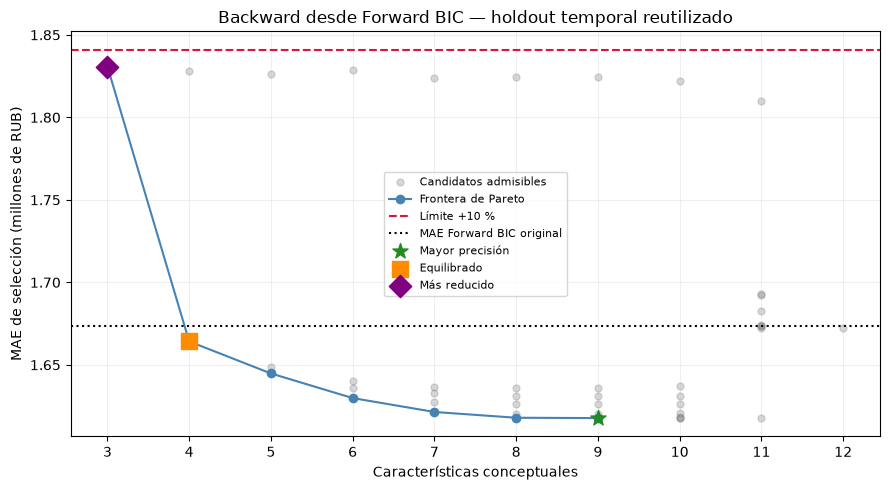

In [ ]:
# Bloque original 57
filas_comparacion_backward = [{'Modelo': 'Forward BIC', 'Características': len(caracteristicas_iniciales_backward), 'Columnas OLS': len(columnas_iniciales_backward), 'MAE (RUB)': mae_referencia_backward, 'Deterioro vs. BIC': 0.0}]
for rol, r in resultados_backward.items():
    registro = r['registro']
    filas_comparacion_backward.append({'Modelo': 'Backward — ' + etiquetas_backward[rol], 'Características': registro['n_caracteristicas'], 'Columnas OLS': registro['n_columnas_OLS'], 'MAE (RUB)': registro['metricas']['validation_mae_rub'], 'Deterioro vs. BIC': registro['deterioro_pct']})
comparacion_backward = pd.DataFrame(filas_comparacion_backward)
presencia_backward = pd.DataFrame([{'Característica': c, 'Forward BIC': 'Sí', **{etiquetas_backward[rol]: 'Sí' if c in r['registro']['caracteristicas'] else 'No' for rol, r in resultados_backward.items()}} for c in caracteristicas_iniciales_backward])
for titulo, tabla in [('Resultados de selección', comparacion_backward), ('Características conservadas', presencia_backward)]:
    texto = '### ' + titulo + '\n\n| ' + ' | '.join(tabla.columns) + ' |\n| ' + ' | '.join(['---'] * len(tabla.columns)) + ' |\n'
    for fila in tabla.itertuples(index=False, name=None):
        texto += '| ' + ' | '.join((f'{v:,.3f}' if isinstance(v, float) else str(v) for v in fila)) + ' |\n'
    pass
pass
fig_backward, ax = plt.subplots(figsize=(9, 5))
ax.scatter(admisibles_max_backward.n_caracteristicas, admisibles_max_backward.mae_rub / 1000000.0, s=25, alpha=0.3, color='gray', label='Candidatos admisibles')
ax.plot(frontera_pareto_backward.n_caracteristicas, frontera_pareto_backward.mae_rub / 1000000.0, color='steelblue', marker='o', label='Frontera de Pareto')
ax.axhline(limite_max_backward / 1000000.0, color='crimson', linestyle='--', label='Límite +10 %')
ax.axhline(mae_referencia_backward / 1000000.0, color='black', linestyle=':', label='MAE Forward BIC original')
for (rol, r), color, marca in zip(resultados_backward.items(), ['forestgreen', 'darkorange', 'purple'], ['*', 's', 'D']):
    registro = r['registro']
    ax.scatter(registro['n_caracteristicas'], registro['metricas']['validation_mae_rub'] / 1000000.0, s=130, color=color, marker=marca, zorder=5, label=etiquetas_backward[rol])
ax.set(xlabel='Características conceptuales', ylabel='MAE de selección (millones de RUB)', title='Backward desde Forward BIC — holdout temporal reutilizado')
ax.set_xticks(np.arange(int(admisibles_max_backward.n_caracteristicas.min()), int(admisibles_max_backward.n_caracteristicas.max()) + 1))
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig_backward.tight_layout()
plt.show()


In [ ]:
# Agrupar resultados idénticos de las once tolerancias, sin descartar pruebas.
resumen_tolerancias_ols = tabla_tolerancias_backward.drop(columns='Tolerancia').drop_duplicates().copy()
resumen_tolerancias_ols.insert(0, 'Tolerancias', [
    ', '.join(tabla_tolerancias_backward.loc[
        tabla_tolerancias_backward['Características'].eq(fila['Características']) &
        tabla_tolerancias_backward['Columnas OLS'].eq(fila['Columnas OLS']), 'Tolerancia'])
    for _, fila in resumen_tolerancias_ols.iterrows()])
display(resumen_tolerancias_ols)


Tolerancias,Características,Columnas OLS,MAE (RUB),Deterioro real
"0 %, 1 %, 2 %, 3 %, 4 %, 5 %, 6 %, 7 %, 8 %, 9 %",4,113,"1,664,212.31",-0.563 %
10 %,3,112,"1,830,837.53",+9.393 %


In [ ]:
# Bloque original 59
import mlflow.statsmodels
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
experimento_backward = mlflow.set_experiment('Propiedades_Nuevas_OLS')
assert experimento_backward.experiment_id == run_origen_backward.info.experiment_id
nombres_runs_backward = {'MenorMAE': 'Backward_MenorMAE_LogPrice', 'Equilibrado': 'Backward_Equilibrado_LogPrice', 'MinFeatures': 'Backward_MinFeatures_LogPrice'}
versiones_backward = {p: version(p) for p in ['statsmodels', 'numpy', 'pandas', 'scipy', 'mlflow']}
notebook_backward = raiz_proyecto / 'Ventas' / 'Propiedades_Nuevas' / 'Modelo_OLS.ipynb'
codigo_backward = [''.join(c['source']) for c in json.loads(notebook_backward.read_text(encoding='utf-8'))['cells'] if c['cell_type'] == 'code']
sha_codigo_backward = hashlib.sha256('\n'.join(codigo_backward).encode('utf-8')).hexdigest()
git_backward = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=raiz_proyecto, capture_output=True, text=True)
commit_backward = git_backward.stdout.strip() if git_backward.returncode == 0 else 'no_disponible'
git_dirty_backward = bool(subprocess.run(['git', 'status', '--porcelain'], cwd=raiz_proyecto, capture_output=True, text=True).stdout.strip())
registros_mlflow_backward = {}
verificaciones_backward = []
for rol, r in resultados_backward.items():
    registro, modelo = (r['registro'], r['modelo'])
    parametros = {'algoritmo': 'Backward Selection', 'modelo_origen': 'Forward BIC', 'origen_run_id': run_origen_backward_id, 'rol': rol, 'tolerancia_aplicada_pct': r['tolerancia'], 'tolerancia_max_pct': 10, 'grid_tolerancias': '0..10_incremento_1pct', 'mae_referencia_original_rub': mae_referencia_backward, 'caracteristicas_iniciales': len(caracteristicas_iniciales_backward), 'caracteristicas_seleccionadas': json.dumps(registro['caracteristicas'], ensure_ascii=False), 'n_caracteristicas': registro['n_caracteristicas'], 'n_columnas_OLS': registro['n_columnas_OLS'], 'n_parametros_estimables': int(modelo.model.rank), 'target': 'log_price_rub', 'n_train': len(X_train), 'n_folds': len(folds_backward), 'protocolo_validacion': protocolo_validacion_baseline['tipo'], 'fecha_inicio_validacion': protocolo_validacion_baseline['inicio_validacion'], 'alcance_metricas': 'seleccion_holdout_reutilizado_no_generalizacion_independiente', 'test_evaluado': False, 'busqueda': 'voraz_hasta_intercepto_sin_detener_por_tolerancia', 'regla_equilibrado': 'distancia_euclidea_ideal_normalizada_pesos_iguales_pareto_interior', 'n_subconjuntos_evaluados': len(evaluaciones_backward), 'n_puntos_pareto': len(frontera_pareto_backward), 'retransformacion': 'exp_por_smearing_Duan_estimado_en_ajuste', 'smearing_Train': r['factor_smearing_Train'], 'dataset': 'newbuilds_ols.csv', 'dataset_sha256': run_origen_backward.data.params['dataset_sha256'], 'codigo_sha256': sha_codigo_backward, 'git_commit': commit_backward, 'git_dirty': git_dirty_backward, **{f'version_{p}': v for p, v in versiones_backward.items()}}
    coeficientes = pd.DataFrame({'columna': modelo.params.index, 'coef_log': modelo.params.to_numpy(), 'error_estandar': modelo.bse.to_numpy(), 'p_value': modelo.pvalues.to_numpy()})
    textos = {'resumen_OLS_log.txt': modelo.summary().as_text(), 'coeficientes_log.csv': coeficientes.to_csv(index=False), 'comparacion_modelos.csv': comparacion_backward.to_csv(index=False), 'tolerancias.csv': tabla_tolerancias_backward.to_csv(index=False), 'presencia_caracteristicas.csv': presencia_backward.to_csv(index=False), 'trayectoria_resumida.csv': historial_backward.to_csv(index=False), 'frontera_pareto.csv': frontera_pareto_backward.drop(columns='caracteristicas').to_csv(index=False), 'metricas_folds_seleccion.csv': pd.DataFrame(registro['folds']).to_csv(index=False), 'alcance_metricas.md': 'Métricas de selección sobre el holdout reutilizado para elegir subconjuntos y roles. No son estimaciones independientes de generalización. La lista inicial de 12 características fue seleccionada con todo Train, incluido el holdout. El MAE de referencia original corresponde al procedimiento Forward BIC (su selección interna podía tener otro subconjunto). Test permanece reservado.'}
    jsons = {'caracteristicas_seleccionadas.json': {'rol': rol, 'subset_id': registro['subset_id'], 'caracteristicas': registro['caracteristicas'], 'columnas_OLS': registro['columnas'], 'tolerancia_pct': r['tolerancia'], 'deterioro_real_pct': registro['deterioro_pct']}, 'caracteristicas_columnas_OLS.json': {c: grupos_backward[c] for c in registro['caracteristicas']}, 'universo_inicial.json': grupos_backward, 'metricas_seleccion.json': {'interpretacion': 'seleccion_no_generalizacion_independiente', 'metricas': r['metricas'], 'folds': registro['folds']}, 'protocolo.json': protocolo_validacion_baseline, 'referencia_origen.json': {'run_id': run_origen_backward_id, 'mae_original': mae_referencia_backward, 'caracteristicas_definitivas_origen': caracteristicas_iniciales_backward, 'reevaluacion_fija_inicial': inicial_backward['metricas'], 'limite_10pct': limite_max_backward}, 'criterio_compromisos.json': {'regla': 'pareto_y_distancia_normalizada_al_ideal_pesos_iguales_entre_interiores', 'elegidos': elegidos_backward, 'ganadores_por_tolerancia': {str(k): v for k, v in ganadores_tolerancias_backward.items()}, 'sin_evaluacion_test': True, 'no_evaluables': no_evaluables_backward}, 'retransformacion.json': {'metodo': 'exp(pred_log)*factor_smearing', 'factor_Train': r['factor_smearing_Train'], 'factores_ajuste_por_fold': [f['smearing'] for f in registro['folds']], 'usa_test': False}, 'preparacion_fold.json': {'medianas_ajuste': {k: float(v) for k, v in parametros_validacion['medianas'].items()}, 'constantes_ajuste': parametros_validacion['constantes'], 'dependencias_ajuste': parametros_validacion['dependientes'], 'fit_solo_ajuste': True}}
    diseno_train = pd.DataFrame({'const': np.ones(len(X_train))}, index=X_train.index).join(X_train[registro['columnas']])
    assert diseno_train.columns.tolist() == modelo.model.exog_names
    with mlflow.start_run(experiment_id=experimento_backward.experiment_id, run_name=nombres_runs_backward[rol], tags={'segmento': 'propiedades_nuevas', 'familia_modelo': 'OLS', 'iteracion': 'backward', 'target': 'log_price_rub', 'seleccion': 'backward_por_caracteristicas', 'rol': rol, 'origen': 'Forward_BIC', 'test_evaluado': 'false', 'alcance_metricas': 'seleccion_no_generalizacion_independiente'}) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics(r['metricas'])
        for nombre, texto in textos.items():
            mlflow.log_text(texto, nombre)
        for nombre, contenido in jsons.items():
            mlflow.log_dict(contenido, nombre)
        mlflow.log_figure(fig_backward, 'compromisos_caracteristicas_MAE.png')
        info_modelo = mlflow.statsmodels.log_model(deepcopy(modelo), name='modelo', remove_data=True, signature=infer_signature(diseno_train.head(5), modelo.predict(diseno_train.head(5))), pip_requirements=[f'{p}=={v}' for p, v in versiones_backward.items()])
        info_registro = {'run_id': run.info.run_id, 'experiment_id': experimento_backward.experiment_id, 'model_uri': info_modelo.model_uri, 'model_id': info_modelo.model_id}
        mlflow.log_dict(info_registro, 'modelo_uri.json')
    registros_mlflow_backward[rol] = info_registro
    remoto = cliente_baseline.get_run(info_registro['run_id'])
    assert remoto.info.status == 'FINISHED' and remoto.data.tags['mlflow.runName'] == nombres_runs_backward[rol]
    assert remoto.info.experiment_id == experimento_backward.experiment_id
    for k, v in parametros.items():
        assert remoto.data.params[k] == str(v)
    for k, v in r['metricas'].items():
        assert math.isclose(remoto.data.metrics[k], v, rel_tol=1e-10, abs_tol=1e-12)
    assert not any((k.lower().startswith('test_') or k.lower().endswith('_test') for k in remoto.data.metrics))
    assert remoto.data.tags['alcance_metricas'] == 'seleccion_no_generalizacion_independiente'
    assert set(textos) | set(jsons) | {'compromisos_caracteristicas_MAE.png', 'modelo_uri.json'} <= {a.path for a in cliente_baseline.list_artifacts(info_registro['run_id'])}
    with TemporaryDirectory(prefix='backward_verificacion_') as temporal:
        for nombre, esperado in jsons.items():
            descargado = cliente_baseline.download_artifacts(info_registro['run_id'], nombre, dst_path=temporal)
            assert json.loads(Path(descargado).read_text(encoding='utf-8')) == esperado
        for nombre, esperado in textos.items():
            descargado = cliente_baseline.download_artifacts(info_registro['run_id'], nombre, dst_path=temporal)
            if nombre.endswith('.csv'):
                pd.testing.assert_frame_equal(pd.read_csv(descargado), pd.read_csv(StringIO(esperado)), check_exact=False, rtol=1e-12, atol=1e-12)
            else:
                assert Path(descargado).read_text(encoding='utf-8').splitlines() == esperado.splitlines()
        grafico = cliente_baseline.download_artifacts(info_registro['run_id'], 'compromisos_caracteristicas_MAE.png', dst_path=temporal)
        assert Path(grafico).stat().st_size > 0
        recuperado = mlflow.statsmodels.load_model(info_registro['model_uri'], dst_path=temporal)
        assert recuperado.model.exog_names == modelo.model.exog_names
        np.testing.assert_allclose(recuperado.predict(diseno_train.head(20)), modelo.predict(diseno_train.head(20)), rtol=1e-10, atol=1e-10)
    assert cliente_baseline.get_logged_model(info_registro['model_id']).source_run_id == info_registro['run_id']
    url = tracking_uri_dagshub + '/#/experiments/' + info_registro['experiment_id'] + '/runs/' + info_registro['run_id']
    verificaciones_backward.append({'rol': rol, 'run_id': info_registro['run_id'], 'estado': 'FINISHED', 'verificado': True, 'url': url})
    pass
assert len({r['run_id'] for r in registros_mlflow_backward.values()}) == len(resultados_backward)
assert not {r['run_id'] for r in registros_mlflow_backward.values()} & set(snapshots_remotos_backward)
for run_id, esperado in snapshots_remotos_backward.items():
    ref = cliente_baseline.get_run(run_id)
    assert {'params': dict(ref.data.params), 'metrics': dict(ref.data.metrics), 'tags': dict(ref.data.tags), 'estado': ref.info.status, 'artefactos': sorted((a.path for a in cliente_baseline.list_artifacts(run_id)))} == esperado
for k, v in {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() == huellas_backward[k]
assert mlflow.active_run() is None
pass

# Bloque original 61
for rol, r in resultados_backward.items():
    registro = r['registro']
    eliminadas = [c for c in caracteristicas_iniciales_backward if c not in registro['caracteristicas']]
    error_adicional = registro['metricas']['validation_mae_rub'] - mae_referencia_backward
    pass
for verificacion in verificaciones_backward:
    pass
pass


## Evaluación final · Subconjuntos congelados

Reajuste de los diseños históricos de 12, 9 y 4 características con todo Train; evaluación sobre las mismas 1.600 filas Test.
Las listas, el intercepto y el smearing se mantienen; Test no interviene en la preparación o selección. El diseño de tres características no fue evaluado en Test.


In [ ]:
# Bloque original 63
from IPython.display import Markdown
from tempfile import TemporaryDirectory
from copy import deepcopy
from mlflow.models import infer_signature
from threadpoolctl import threadpool_limits
import math
assert (len(X_train), len(X_test)) == (6400, 1600)
assert X_train.columns.equals(X_test.columns)
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
fuentes_test_final = {'Forward BIC': ('af758e48730d4a75ae0e18bb8168d241', 'Test_Final_Forward_BIC', 12, 122), 'Backward — Mayor precisión': ('eb073b96f51c4f1fb9cc77f7cbafa900', 'Test_Final_Backward_Precision', 9, 118), 'Backward — Equilibrado': ('bb98ead9148f4e75b08628394d890937', 'Test_Final_Backward_Equilibrado', 4, 113)}
congelados_test_final = {}
snapshots_test_final = {}
huellas_test_final = {k: hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() for k, v in {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test, 'precio_train': price_rub_train, 'precio_test': price_rub_test}.items()}
for nombre, (run_id, nombre_run, n_features, n_cols) in fuentes_test_final.items():
    remoto = cliente_baseline.get_run(run_id)
    assert remoto.info.status == 'FINISHED'
    assert remoto.data.params['dataset_sha256'] == hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
    assert cliente_baseline.get_experiment(remoto.info.experiment_id).name == 'Propiedades_Nuevas_OLS'
    snapshots_test_final[run_id] = {'params': dict(remoto.data.params), 'metrics': dict(remoto.data.metrics), 'tags': dict(remoto.data.tags), 'status': remoto.info.status, 'artefactos': sorted((a.path for a in cliente_baseline.list_artifacts(run_id)))}
    es_forward = nombre == 'Forward BIC'
    archivo_seleccion = 'seleccion_forward.json' if es_forward else 'caracteristicas_seleccionadas.json'
    archivo_protocolo = 'validacion.json' if es_forward else 'protocolo.json'
    with TemporaryDirectory(prefix='test_origen_') as temporal:
        originales = {}
        for archivo in [archivo_seleccion, 'caracteristicas_columnas_OLS.json', archivo_protocolo]:
            local = cliente_baseline.download_artifacts(run_id, archivo, dst_path=temporal)
            originales[archivo] = json.loads(Path(local).read_text(encoding='utf-8'))
    seleccion = originales[archivo_seleccion]
    features = seleccion['seleccionadas' if es_forward else 'caracteristicas']
    columnas = seleccion['columnas_OLS']
    mapa = {c: diccionario_caracteristicas[c].copy() for c in features}
    assert all((originales['caracteristicas_columnas_OLS.json'][c] == mapa[c] for c in features))
    assert columnas == [v for c in features for v in mapa[c]]
    assert (len(features), len(columnas)) == (n_features, n_cols)
    assert len(set(columnas)) == n_cols and set(columnas).issubset(X_train.columns)
    protocolo = originales[archivo_protocolo]
    if es_forward:
        protocolo = protocolo['protocolo']
    assert protocolo == protocolo_validacion_baseline
    congelados_test_final[nombre] = {'origen_run_id': run_id, 'nombre_run': nombre_run, 'caracteristicas': features, 'columnas_OLS': columnas, 'mapa': mapa, 'validation_mae_rub': float(remoto.data.metrics['validation_mae_rub']), 'seleccion_original': 'Forward BIC' if es_forward else 'Backward con tolerancia progresiva', 'dataset_sha256': remoto.data.params['dataset_sha256']}
pass
pass

# Bloque original 65
resultados_test_final = {}
filas_test_final = []
with threadpool_limits(limits=1, user_api='blas'):
    for nombre, config in congelados_test_final.items():
        columnas = config['columnas_OLS']
        a = pd.DataFrame({'const': np.ones(len(X_train))}, index=X_train.index).join(X_train[columnas])
        b = pd.DataFrame({'const': np.ones(len(X_test))}, index=X_test.index).join(X_test[columnas])
        assert a.columns.equals(b.columns) and a.index.equals(y_train.index) and b.index.equals(y_test.index)
        assert np.isfinite(a.to_numpy()).all() and np.isfinite(b.to_numpy()).all()
        modelo = sm.OLS(y_train, a, missing='raise').fit()
        assert modelo.model.rank == len(columnas) + 1
        factor = float(np.exp(modelo.resid).mean())
        pred_log = modelo.predict(b)
        pred_rub = np.exp(pred_log) * factor
        assert len(pred_rub) == 1600 and np.isfinite(pred_rub).all() and pred_rub.gt(0).all()
        metricas = {'test_mae_rub': float(mean_absolute_error(price_rub_test, pred_rub)), 'test_rmse_rub': float(np.sqrt(mean_squared_error(price_rub_test, pred_rub))), 'test_r2_rub': float(r2_score(price_rub_test, pred_rub)), 'validation_mae_rub': config['validation_mae_rub']}
        metricas['mae_test_vs_validation_pct'] = 100 * (metricas['test_mae_rub'] / metricas['validation_mae_rub'] - 1)
        resultados_test_final[nombre] = {'config': config, 'modelo': modelo, 'smearing_Train': factor, 'metricas': metricas, 'diseno_train': a, 'predicciones_test': metadatos_test.assign(price_rub_real=price_rub_test, prediccion_log=pred_log, prediccion_rub=pred_rub)}
        filas_test_final.append({'Modelo': nombre, 'Características': len(config['caracteristicas']), 'Columnas OLS': len(columnas), 'MAE Validación (RUB)': metricas['validation_mae_rub'], 'MAE Test (RUB)': metricas['test_mae_rub'], 'RMSE Test (RUB)': metricas['test_rmse_rub'], 'R² Test': metricas['test_r2_rub']})
comparacion_test_final = pd.DataFrame(filas_test_final)
mae_forward_test_final = resultados_test_final['Forward BIC']['metricas']['test_mae_rub']
for r in resultados_test_final.values():
    r['metricas']['mae_test_vs_forward_bic_pct'] = 100 * (r['metricas']['test_mae_rub'] / mae_forward_test_final - 1)
lineas_tabla_test_final = ['| ' + ' | '.join(comparacion_test_final.columns) + ' |', '|---|---|---|---|---|---|---|']
for fila in comparacion_test_final.to_dict('records'):
    valores = [fila['Modelo'], str(fila['Características']), str(fila['Columnas OLS'])]
    valores += [f'{fila[c]:,.0f}'.replace(',', '.') for c in ['MAE Validación (RUB)', 'MAE Test (RUB)', 'RMSE Test (RUB)']]
    valores += [f"{fila['R² Test']:.4f}"]
    lineas_tabla_test_final.append('| ' + ' | '.join(valores) + ' |')
tabla_markdown_test_final = chr(10).join(lineas_tabla_test_final)
pass
for nombre, r in resultados_test_final.items():
    m = r['metricas']
    pass


In [ ]:
# Bloque original 67
import mlflow.statsmodels
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
experimento_test_final = mlflow.set_experiment('Propiedades_Nuevas_OLS')
assert experimento_test_final.experiment_id == '3'
versiones_test_final = {p: version(p) for p in ['statsmodels', 'numpy', 'pandas', 'scipy', 'mlflow']}
ruta_notebook_test_final = raiz_proyecto / 'Ventas' / 'Propiedades_Nuevas' / 'Modelo_OLS.ipynb'
codigo_test_final = [''.join(c['source']) for c in json.loads(ruta_notebook_test_final.read_text(encoding='utf-8'))['cells'] if c['cell_type'] == 'code']
sha_codigo_test_final = hashlib.sha256(chr(10).join(codigo_test_final).encode('utf-8')).hexdigest()
registros_test_final = {}
for nombre, r in resultados_test_final.items():
    config, modelo = (r['config'], r['modelo'])
    parametros = {'modelo': 'OLS', 'target': 'log_price_rub', 'seleccion_original': config['seleccion_original'], 'origen_run_id': config['origen_run_id'], 'n_caracteristicas': len(config['caracteristicas']), 'n_columnas_OLS': len(config['columnas_OLS']), 'intercepto': True, 'n_train': len(X_train), 'n_test': len(X_test), 'protocolo_particion': 'cronologico_80_20_orden_fecha_id_sin_cambios', 'fecha_fin_train': df_train.date_posted_dt.max().date().isoformat(), 'fecha_inicio_test': df_test.date_posted_dt.min().date().isoformat(), 'retransformacion': 'exp(pred_log)*mean(exp(residuo_Train)); smearing_Duan', 'smearing_Train': r['smearing_Train'], 'ajuste_correccion': 'solo_Train', 'dataset_sha256': config['dataset_sha256'], 'codigo_sha256': sha_codigo_test_final, **{f'version_{p}': v for p, v in versiones_test_final.items()}}
    jsons = {'caracteristicas_seleccionadas.json': {'caracteristicas': config['caracteristicas'], 'columnas_OLS': config['columnas_OLS'], 'origen_run_id': config['origen_run_id']}, 'caracteristicas_columnas_OLS.json': config['mapa'], 'metricas.json': r['metricas'], 'retransformacion.json': {'metodo': 'exp(pred_log)*factor_smearing', 'factor_Train': r['smearing_Train'], 'estimado_con': '6400 observaciones Train; residuos del modelo definitivo', 'usa_test_para_ajuste': False}, 'protocolo.json': {'particion': '80/20 cronológica por fecha e ID', 'n_train': 6400, 'n_test': 1600, 'complejos_compartidos': len(complejos_compartidos), 'validacion_historica': protocolo_validacion_baseline, 'transformaciones': 'matrices existentes; sin recalcular parámetros con Test', 'seleccion_con_test': False}}
    textos = {'comparacion_final.md': tabla_markdown_test_final, 'comparacion_final.csv': comparacion_test_final.to_csv(index=False), 'resumen_OLS_Train.txt': modelo.summary().as_text(), 'alcance.md': 'Evaluación final descriptiva sobre Test reservado. Los MAE de validación se conservan del run de origen. Backward reutilizó el holdout para selección; Forward validó su procedimiento interno. No son estimaciones independientes y equivalentes de los tres subconjuntos definitivos. Hay complejos compartidos entre Train y Test: se evalúan anuncios posteriores, no exclusivamente complejos nuevos. No se vuelve a seleccionar ni ajustar usando Test.'}
    a = r['diseno_train']
    with mlflow.start_run(experiment_id=experimento_test_final.experiment_id, run_name=config['nombre_run'], tags={'segmento': 'propiedades_nuevas', 'familia_modelo': 'OLS', 'iteracion': 'test_final', 'origen_run_id': config['origen_run_id'], 'target': 'log_price_rub', 'seleccion_con_test': 'false'}) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics(r['metricas'])
        for archivo, contenido in jsons.items():
            mlflow.log_dict(contenido, archivo)
        for archivo, contenido in textos.items():
            mlflow.log_text(contenido, archivo)
        info = mlflow.statsmodels.log_model(deepcopy(modelo), name='modelo', remove_data=True, signature=infer_signature(a.head(5), modelo.predict(a.head(5))), pip_requirements=[f'{p}=={v}' for p, v in versiones_test_final.items()])
        registro = {'run_id': run.info.run_id, 'model_uri': info.model_uri, 'model_id': info.model_id, 'experiment_id': experimento_test_final.experiment_id}
        mlflow.log_dict(registro, 'modelo_uri.json')
    registros_test_final[nombre] = registro
    remoto = cliente_baseline.get_run(registro['run_id'])
    assert remoto.info.status == 'FINISHED' and remoto.data.tags['mlflow.runName'] == config['nombre_run']
    for k, v in parametros.items():
        assert remoto.data.params[k] == str(v)
    for k, v in r['metricas'].items():
        assert math.isclose(remoto.data.metrics[k], v, rel_tol=1e-10, abs_tol=1e-12)
    assert set(jsons) | set(textos) | {'modelo_uri.json'} <= {a.path for a in cliente_baseline.list_artifacts(registro['run_id'])}
    with TemporaryDirectory(prefix='test_verificacion_') as temporal:
        for archivo, contenido in {**jsons, 'modelo_uri.json': registro}.items():
            local = cliente_baseline.download_artifacts(registro['run_id'], archivo, dst_path=temporal)
            assert json.loads(Path(local).read_text(encoding='utf-8')) == contenido
        for archivo, contenido in textos.items():
            local = cliente_baseline.download_artifacts(registro['run_id'], archivo, dst_path=temporal)
            if archivo.endswith('.csv'):
                from io import StringIO
                pd.testing.assert_frame_equal(pd.read_csv(local), pd.read_csv(StringIO(contenido)), check_exact=False, rtol=1e-12, atol=1e-12)
            else:
                assert Path(local).read_text(encoding='utf-8').splitlines() == contenido.splitlines()
        recuperado = mlflow.statsmodels.load_model(registro['model_uri'], dst_path=temporal)
        assert recuperado.model.exog_names == a.columns.tolist()
        np.testing.assert_allclose(recuperado.predict(a.head(20)), modelo.predict(a.head(20)), rtol=1e-10, atol=1e-10)
    assert cliente_baseline.get_logged_model(registro['model_id']).source_run_id == registro['run_id']
    pass
assert len({r['run_id'] for r in registros_test_final.values()}) == 3
assert not {r['run_id'] for r in registros_test_final.values()} & set(snapshots_test_final)
for run_id, esperado in snapshots_test_final.items():
    ref = cliente_baseline.get_run(run_id)
    assert {'params': dict(ref.data.params), 'metrics': dict(ref.data.metrics), 'tags': dict(ref.data.tags), 'status': ref.info.status, 'artefactos': sorted((a.path for a in cliente_baseline.list_artifacts(run_id)))} == esperado
for k, v in {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test, 'precio_train': price_rub_train, 'precio_test': price_rub_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v, index=True).values.tobytes()).hexdigest() == huellas_test_final[k]
assert mlflow.active_run() is None
pass

# Bloque original 69
menor_test_final = min(resultados_test_final, key=lambda k: resultados_test_final[k]['metricas']['test_mae_rub'])
precision_test_final = resultados_test_final['Backward — Mayor precisión']['metricas']['test_mae_rub']
equilibrado_test_final = resultados_test_final['Backward — Equilibrado']['metricas']['test_mae_rub']
brecha_equilibrado_test_final = 100 * (equilibrado_test_final / precision_test_final - 1)
conclusiones_test_final = [f"El menor MAE observado sobre las 1.600 filas Test corresponde a **{menor_test_final}**: **{resultados_test_final[menor_test_final]['metricas']['test_mae_rub']:,.0f} RUB**."]
for nombre, r in resultados_test_final.items():
    m = r['metricas']
    conclusiones_test_final.append(f"{nombre}: el MAE Test difiere **{m['mae_test_vs_validation_pct']:+.2f} %** del histórico de validación y **{m['mae_test_vs_forward_bic_pct']:+.2f} %** del MAE Test Forward BIC.")
conclusiones_test_final.append(f'El modelo equilibrado conserva 4 características (113 columnas OLS), frente a 9 (118 columnas) del modelo de mayor precisión en validación. Su diferencia relativa de MAE Test frente a este último es **{brecha_equilibrado_test_final:+.2f} %**. La simplificación conceptual es grande, pero district conserva sus 108 dummies: reducir características no equivale a reducir proporcionalmente parámetros.')
conclusiones_test_final.append('Los porcentajes positivos frente a validación indican mayor error en anuncios posteriores; los negativos indican menor error observado. La comparación está condicionada por el distinto alcance de las métricas históricas y por el cambio de período/precios. No constituye por sí sola una prueba causal de deterioro ni una estimación de incertidumbre.')
conclusiones_test_final.append('El compromiso entre simplicidad y precisión se interpreta con estas diferencias, manteniendo como equilibrado el subconjunto de 4 características previamente seleccionado. El menor error de Test se informa como resultado final descriptivo; no se usa para volver a elegir características. La presencia de complejos compartidos limita la conclusión a anuncios posteriores del universo observado, no a complejos residenciales completamente nuevos. La evaluación final termina aquí, sin nuevos experimentos.')
for texto in conclusiones_test_final:
    pass
for nombre, registro in registros_test_final.items():
    url = tracking_uri_dagshub + '/#/experiments/' + registro['experiment_id'] + '/runs/' + registro['run_id']
    pass


## Comparación general

**Ajuste:** mismas 6.400 filas y objetivo logarítmico; R² ajustado, AIC y BIC penalizan parámetros estimables, incluido el intercepto.
**Predicción:** MAE/RMSE en RUB y R² en RUB. El alcance del holdout se informa por separado; sus métricas de validación y selección no equivalen a estimaciones independientes comparables de generalización.


In [ ]:
experimentos_ols = [('Baseline OLS', modelo_ols_baseline, metricas_baseline, caracteristicas_baseline, 'Validación')]
experimentos_ols += [('Forward '+k, r['modelo'], r['metricas'], r['seleccion']['seleccionadas'], 'Validación')
                    for k, r in resultados_forward.items()]
experimentos_ols += [('Backward — '+etiquetas_backward[k], r['modelo'], r['metricas'], r['registro']['caracteristicas'], 'Selección')
                    for k, r in resultados_backward.items()]
comparacion_ajuste_ols = pd.DataFrame([
    {'Modelo': nombre, 'Características': len(features), 'Columnas OLS': len(modelo.params)-1,
     'R² Train (log)': modelo.rsquared, 'R² ajustado (log)': modelo.rsquared_adj,
     'AIC': modelo.aic, 'BIC': modelo.bic}
    for nombre, modelo, metricas, features, alcance in experimentos_ols])
comparacion_error_ols = pd.DataFrame([
    {'Modelo': nombre, 'Holdout': alcance, 'MAE holdout (RUB)': m['validation_mae_rub'],
     'RMSE holdout (RUB)': m['validation_rmse_rub'], 'R² holdout (RUB)': m['validation_r2_rub'],
     'Δ MAE vs. baseline (%)': 100*(m['validation_mae_rub']/metricas_baseline['validation_mae_rub']-1)}
    for nombre, modelo, m, features, alcance in experimentos_ols])
display(comparacion_ajuste_ols)
display(comparacion_error_ols)


Modelo,Características,Columnas OLS,R² Train (log),R² ajustado (log),AIC,BIC
Baseline OLS,24,155,0.965743,0.964893,"-9,498.55","-8,443.36"
Forward AIC,20,149,0.965698,0.964880,"-9,502.14","-8,487.54"
Forward BIC,12,122,0.965226,0.964550,"-9,468.71","-8,636.73"
Forward AdjR2,22,153,0.965733,0.964894,"-9,500.69","-8,459.02"
Backward — Mayor precisión,9,118,0.963526,0.962840,"-9,171.15","-8,366.23"
Backward — Equilibrado,4,113,0.962186,0.961506,"-8,950.23","-8,179.13"
Backward — Más reducido,3,112,0.947927,0.946999,"-6,904.50","-6,140.16"


Modelo,Holdout,MAE holdout (RUB),RMSE holdout (RUB),R² holdout (RUB),Δ MAE vs. baseline (%)
Baseline OLS,Validación,"1,745,629.06","2,670,162.41",0.911404,0.00
Forward AIC,Validación,"1,749,158.16","2,678,705.42",0.910836,0.20
Forward BIC,Validación,"1,673,633.88","2,586,593.16",0.916863,-4.12
Forward AdjR2,Validación,"1,747,186.03","2,668,123.72",0.911539,0.09
Backward — Mayor precisión,Selección,"1,617,737.87","2,512,210.25",0.921575,-7.33
Backward — Equilibrado,Selección,"1,664,212.31","2,585,435.90",0.916937,-4.66
Backward — Más reducido,Selección,"1,830,837.53","2,741,556.68",0.906603,4.88


In [ ]:
comparacion_test_ols = comparacion_test_final.rename(columns={'MAE Validación (RUB)': 'MAE histórico (RUB)'}).copy()
comparacion_test_ols['Δ MAE Test vs. BIC (%)'] = [
    resultados_test_final[nombre]['metricas']['mae_test_vs_forward_bic_pct'] for nombre in comparacion_test_ols['Modelo']]
display(comparacion_test_ols)


Modelo,Características,Columnas OLS,MAE histórico (RUB),MAE Test (RUB),RMSE Test (RUB),R² Test,Δ MAE Test vs. BIC (%)
Forward BIC,12,122,"1,673,633.88","1,707,247.56","2,667,095.02",0.908745,0.00
Backward — Mayor precisión,9,118,"1,617,737.87","1,813,603.19","2,820,654.54",0.897934,6.23
Backward — Equilibrado,4,113,"1,664,212.31","1,844,176.78","2,842,102.55",0.896376,8.02


El MAE histórico de Forward BIC corresponde a diez características seleccionadas dentro del ajuste interno, frente a doce definitivas.
Su reevaluación fija inicial en Backward dio 1.672.481,78 RUB, pero las tolerancias conservaron como referencia los 1.673.633,88 RUB originales.
Los historiales, candidatos, tolerancias 0–10 %, VIF, influencia y mapas de bloques permanecen en memoria y en los artefactos remotos.


## Comparación final · Baseline Log vs. Forward BIC

Forward BIC minimiza BIC durante la selección y obtuvo el menor MAE de validación entre los Forward; también fue el mejor de los tres diseños congelados evaluados en Test.
Aquí se contrasta con el baseline en **las mismas 6.400 filas Train** (objetivo logarítmico) y **el mismo holdout de 1.280 filas** (métricas en RUB, smearing estimado en el ajuste).
El holdout evalúa el procedimiento Forward, con diez características internas, frente a doce definitivas. Los gráficos usan los residuos de los dos ajustes definitivos sobre Train. No se compara Test: el baseline no fue evaluado allí.


In [ ]:
from scipy.stats import norm
from statsmodels.nonparametric.smoothers_lowess import lowess

modelos_comparacion_final = {'Baseline Log': modelo_ols_baseline, 'Forward BIC': modelos_forward['BIC']}
baseline_final, bic_final = modelos_comparacion_final.values()
assert baseline_final.nobs == bic_final.nobs == len(X_train) == 6400
assert list(baseline_final.model.data.row_labels) == list(bic_final.model.data.row_labels)
np.testing.assert_array_equal(baseline_final.model.endog, bic_final.model.endog)
assert len(indices_validacion_interna) == 1280 and len(indices_ajuste_interno) == 5120

# Las métricas se leen de los ajustes y resultados existentes; no se vuelve a entrenar.
metricas_bic_final = resultados_forward['BIC']['metricas']
def formato_comparacion_final(valor, decimales):
    return f'{valor:,.{decimales}f}'

filas_comparacion_final = []
for metrica, base, bic, sentido, decimales in [
    ('R² · Train (log)', baseline_final.rsquared, bic_final.rsquared, 'max', 6),
    ('R² ajustado · Train (log)', baseline_final.rsquared_adj, bic_final.rsquared_adj, 'max', 6),
    ('AIC · Train (log)', baseline_final.aic, bic_final.aic, 'min', 2),
    ('BIC · Train (log)', baseline_final.bic, bic_final.bic, 'min', 2),
    ('MAE · holdout (RUB)', metricas_baseline['validation_mae_rub'], metricas_bic_final['validation_mae_rub'], 'min', 2),
    ('RMSE · holdout (RUB)', metricas_baseline['validation_rmse_rub'], metricas_bic_final['validation_rmse_rub'], 'min', 2),
    ('R² · holdout (RUB)', metricas_baseline['validation_r2_rub'], metricas_bic_final['validation_r2_rub'], 'max', 6),
]:
    empate = np.isclose(base, bic, rtol=0, atol=1e-10)
    gana_bic = bic < base if sentido == 'min' else bic > base
    filas_comparacion_final.append({
        'Métrica': metrica, 'Baseline Log': formato_comparacion_final(base, decimales),
        'Forward BIC': formato_comparacion_final(bic, decimales),
        'Δ (Forward − Base)': formato_comparacion_final(bic-base, decimales),
        'Resultado favorable': 'Empate' if empate else ('Forward BIC' if gana_bic else 'Baseline Log')})
tabla_baseline_vs_bic = pd.DataFrame(filas_comparacion_final)
display(tabla_baseline_vs_bic)

# Residuos studentizados internos: e_i / [sigma_hat * sqrt(1-h_ii)], misma definición.
# Se aprovecha la influencia del baseline ya calculada si está disponible.
residuos_comparacion_final = {}
for nombre, modelo in modelos_comparacion_final.items():
    influencia = influencia_baseline if nombre == 'Baseline Log' and 'influencia_baseline' in globals() else modelo.get_influence()
    residuos_comparacion_final[nombre] = {
        'ajustados': np.asarray(modelo.fittedvalues),
        'student': np.asarray(influencia.resid_studentized_internal),
    }
    assert np.isfinite(residuos_comparacion_final[nombre]['student']).all()


Métrica,Baseline Log,Forward BIC,Δ (Forward − Base),Resultado favorable
R² · Train (log),0.965743,0.965226,-0.000517,Baseline Log
R² ajustado · Train (log),0.964893,0.964550,-0.000342,Baseline Log
AIC · Train (log),"-9,498.55","-9,468.71",29.84,Baseline Log
BIC · Train (log),"-8,443.36","-8,636.73",-193.37,Forward BIC
MAE · holdout (RUB),"1,745,629.06","1,673,633.88","-71,995.18",Forward BIC
RMSE · holdout (RUB),"2,670,162.41","2,586,593.16","-83,569.26",Forward BIC
R² · holdout (RUB),0.911404,0.916863,0.005459,Forward BIC


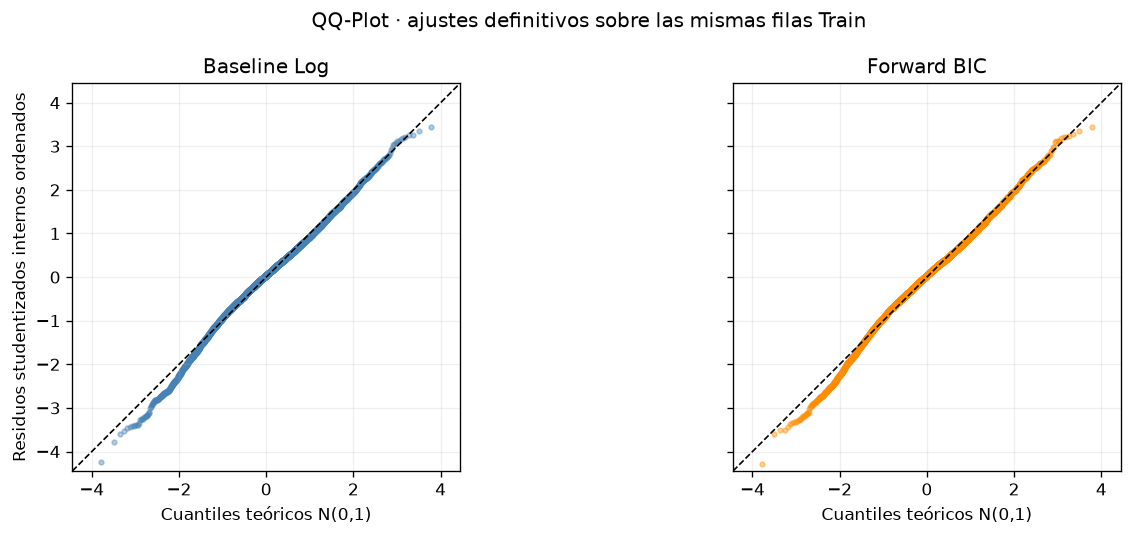

In [ ]:
# QQ de los mismos residuos studentizados internos frente a N(0,1); referencia y=x.
n_qq_final = len(X_train)
cuantiles_qq_final = norm.ppf((np.arange(n_qq_final)+.5)/n_qq_final)
limite_qq_final = max(abs(cuantiles_qq_final).max(),
                      max(abs(v['student']).max() for v in residuos_comparacion_final.values())) * 1.04
fig_qq_comparacion, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, (nombre, datos), color in zip(axes, residuos_comparacion_final.items(), ['steelblue', 'darkorange']):
    ax.scatter(cuantiles_qq_final, np.sort(datos['student']), s=8, alpha=.4, color=color, rasterized=True)
    ax.plot([-limite_qq_final, limite_qq_final], [-limite_qq_final, limite_qq_final], 'k--', linewidth=1)
    ax.set(title=nombre, xlabel='Cuantiles teóricos N(0,1)', xlim=(-limite_qq_final, limite_qq_final),
           ylim=(-limite_qq_final, limite_qq_final))
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=.2)
axes[0].set_ylabel('Residuos studentizados internos ordenados')
fig_qq_comparacion.suptitle('QQ-Plot · ajustes definitivos sobre las mismas filas Train')
fig_qq_comparacion.tight_layout()
plt.show()


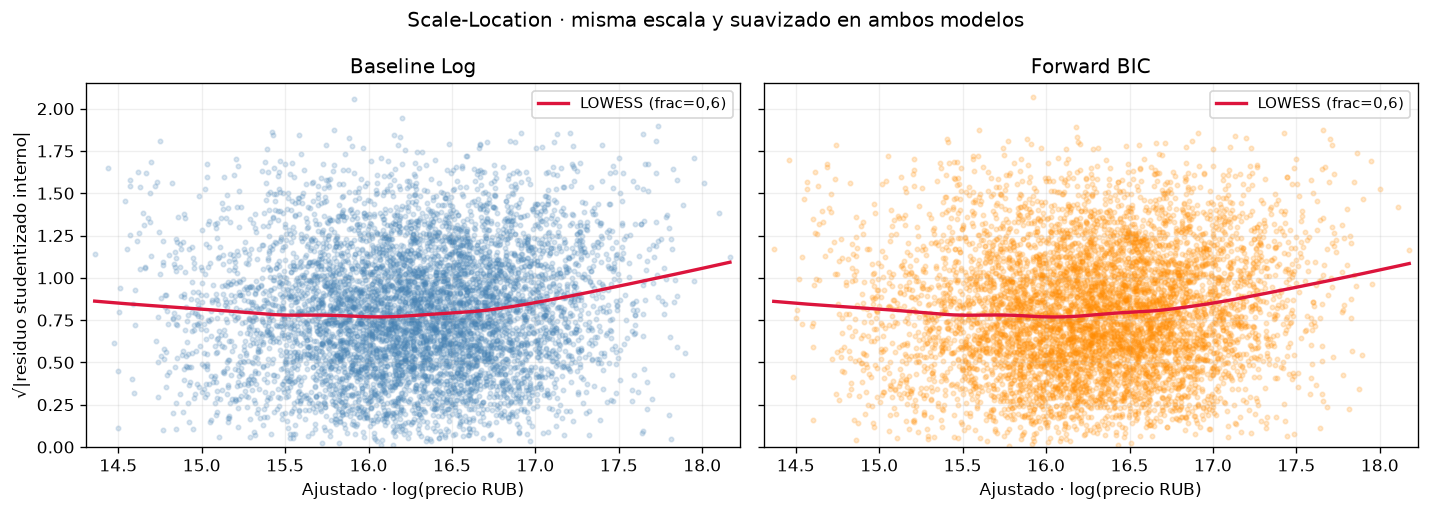

In [ ]:
# Scale-Location: sqrt(|residuo studentizado interno|) frente a ajustado log(RUB).
ajustados_conjuntos_final = np.concatenate([v['ajustados'] for v in residuos_comparacion_final.values()])
limites_x_final = (ajustados_conjuntos_final.min()-.05, ajustados_conjuntos_final.max()+.05)
maximo_y_final = max(np.sqrt(abs(v['student'])).max() for v in residuos_comparacion_final.values()) * 1.04
fig_sl_comparacion, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True, sharey=True)
for ax, (nombre, datos), color in zip(axes, residuos_comparacion_final.items(), ['steelblue', 'darkorange']):
    x, y = datos['ajustados'], np.sqrt(abs(datos['student']))
    ax.scatter(x, y, s=7, alpha=.2, color=color, rasterized=True)
    curva = lowess(y, x, frac=.6, it=0, delta=.01*np.ptp(x), return_sorted=True)
    ax.plot(curva[:, 0], curva[:, 1], color='crimson', linewidth=2, label='LOWESS (frac=0,6)')
    ax.set(title=nombre, xlabel='Ajustado · log(precio RUB)', xlim=limites_x_final, ylim=(0, maximo_y_final))
    ax.grid(alpha=.2)
    ax.legend(loc='upper right', fontsize=9)
axes[0].set_ylabel('√|residuo studentizado interno|')
fig_sl_comparacion.suptitle('Scale-Location · misma escala y suavizado en ambos modelos')
fig_sl_comparacion.tight_layout()
plt.show()


## Conclusión final · Rendimiento y supuestos

**Se mantiene Forward BIC como referencia por su compromiso entre precisión y complejidad.** Elegido mediante selección Forward que minimiza BIC, conserva 12 características y 122 columnas OLS, frente a 24 y 155 del baseline. En el mismo holdout temporal reduce el MAE un **4,12 %** (71.995 RUB) y el RMSE un **3,13 %** (83.569 RUB); el R² en RUB aumenta de **0,911404 a 0,916863**. Estos errores evalúan el procedimiento de selección interna, no de manera independiente el subconjunto definitivo de doce características.

La mejora no es uniforme en todas las métricas: sobre las mismas filas Train, el baseline conserva mayor R² y R² ajustado y menor AIC. Forward BIC reduce BIC en **193,37**, a cambio de aumentar AIC en **29,84** y perder ligeramente ajuste dentro de muestra. Su ventaja se fundamenta en la parsimonia y el error temporal observado, sin demostrar un óptimo global ni diferencias predictivas estadísticamente significativas.

**Los residuos no muestran una mejora visual clara de los supuestos.** Los QQ-Plots se aproximan a la referencia en el centro, pero mantienen desviaciones similares en las colas, especialmente la izquierda. En Scale-Location, ambas curvas presentan curvatura y aumentan hacia precios ajustados altos; la de BIC no resulta claramente más plana. No se concluye normalidad ni homocedasticidad, ni que la selección haya corregido los problemas del baseline. El smearing global tampoco garantiza corregir la media condicional ante heterocedasticidad; la inferencia clásica y los coeficientes requieren cautela.

La recomendación es **predictiva y condicionada al alcance del estudio**: existe un único holdout, Backward reutilizó ese periodo para selección y los 250 complejos aparecen en Train y Test. BIC obtuvo el menor error entre los tres diseños congelados evaluados en Test, pero no hay resultados Test del baseline para afirmar una ventaja sobre él allí. Persisten dependencia entre anuncios, colinealidad, cobertura parcial del catálogo de metro y límites de generalización de los datos hedónicos sintéticos declarados en la auditoría. La disponibilidad histórica de estado/entrega no está acreditada en el baseline; esos bloques no integran BIC definitivo. El resultado respalda utilizar BIC por precisión y simplicidad relativa, sin presentarlo como un modelo cuyos supuestos OLS estén plenamente satisfechos.

El [informe de auditoría](Auditoria_Conclusiones_Propiedades_Nuevas.md) conserva la evidencia histórica; sus índices de celdas corresponden a la organización anterior. Los resultados, listas y referencias remotas originales permanecen en el código plegado.
